# Sesión 3/6 · Python para IA: NumPy, pandas y scikit-learn
**IA aplicada a la ciberseguridad · Máster en Ciberseguridad**  
**Notebook didáctico: código explicado, resultados interpretables y retos resueltos.**

El objetivo es **pasar de los conceptos de preparación de datos a implementar algoritmos y utilizarlos de verdad**. Trabajaremos con conexiones de red, una etiqueta de ataque y registros de autenticación. La secuencia es intencionada: primero aprendemos a operar con números, después a trabajar con tablas y, finalmente, a entrenar, comparar, guardar y aplicar modelos.

| Bloque | Aprenderás a… | Producto observable |
|---|---|---|
| **A · NumPy** | Entender dimensiones, ejes, filtrado, operaciones vectorizadas y distancias. | Tablas numéricas y matriz de distancias. |
| **B · pandas** | Explorar y limpiar flujos de red sin perder su significado. | Tablas de calidad, comparaciones y gráficos. |
| **C · scikit-learn** | Comparar un baseline, regresión logística, árbol y bosque aleatorio. | Exactitud en entrenamiento y prueba, coeficientes y probabilidades. |
| **D · k-NN** | Programar un clasificador por vecinos y contrastarlo con una biblioteca. | Coincidencia entre implementaciones y efecto del escalado. |
| **E · Persistencia** | Serializar un modelo y aplicarlo a un CSV nuevo. | `ids_basico.joblib` y `muestra.csv`. |
| **F · Ampliación** | Resumir eventos de autenticación por ventanas y detectar anomalías. | Alertas y comparación de falsos positivos. |

**Qué se ha respetado:** las fórmulas, los generadores de datos, las semillas aleatorias, las características, los algoritmos, los parámetros esenciales y los archivos de salida del original. Los retos que estaban vacíos se resuelven. Se han mejorado etiquetas, comentarios, presentación y algunas cuestiones de reproducibilidad; se explica dónde hay matices relevantes. La parte F es una ampliación que ahora también queda resuelta.

## Cómo utilizar el cuaderno y vocabulario indispensable

Ejecuta de arriba abajo con **Mayús + Intro**. Si cambias una celda anterior, vuelve a ejecutar las que dependan de ella. Una **sesión del kernel** es la memoria temporal en la que Python conserva variables; reiniciarla las borra. Los CSV y los archivos `.joblib` se guardan en el directorio de trabajo y **sí** permanecen en disco.

- **Observación / muestra / fila:** un flujo de conexión o, en la parte F, un usuario dentro de una ventana temporal.
- **Característica / columna (`X`):** dato disponible para describir la observación: duración, bytes, número de conexiones, etc.
- **Etiqueta (`y`):** respuesta conocida durante el entrenamiento: `0 = benigno`, `1 = ataque`.
- **Conjunto de entrenamiento:** observaciones con las que el modelo aprende. **Conjunto de prueba:** ejemplos reservados para evaluar cómo responde a datos que no empleó al aprender.
- **Modelo:** objeto que aprende un procedimiento o parámetros mediante `.fit(X, y)` y genera predicciones con `.predict(X)`; no es una lista de respuestas memorizadas sin más.
- **Semilla aleatoria (`seed` o `random_state`):** fija la secuencia pseudoaleatoria para poder repetir un experimento; no garantiza idénticos tiempos de ejecución entre equipos.
- **Fuga de información:** usar durante el aprendizaje información del conjunto de prueba o del futuro. Puede producir una evaluación engañosamente buena.

**Origen de los datos.** En la parte B se usa un **generador sintético inspirado en el formato CICIDS2017**, no el CICIDS2017 oficial. En las partes C–E se cargan los archivos públicos **NSL-KDD** (`KDDTrain+.txt` y `KDDTest+.txt`) con divisiones ya definidas. La parte F vuelve a emplear eventos ficticios; ninguno de esos ejemplos demuestra por sí solo que un detector funcionará en una red real.

**Requisitos:** Python con NumPy, pandas, Matplotlib, seaborn, scikit-learn y joblib. La primera ejecución necesita acceso a internet para descargar NSL-KDD salvo que sus dos archivos ya estén en `data/`. Las bibliotecas `xgboost` y `lightgbm`, presentes en la instalación del original, no se utilizan en esta sesión y no se instalan automáticamente; así se evitan dependencias innecesarias sin alterar ningún modelo ejecutado.

## Preparación · Bibliotecas y archivos de trabajo

**Objetivo:** disponer de las mismas funciones y datos cada vez que reiniciamos el kernel.

Una **biblioteca** es código reutilizable creado por otros: NumPy opera con arrays; pandas manipula tablas (`DataFrame`); Matplotlib y seaborn dibujan gráficos; scikit-learn contiene algoritmos de ML; joblib guarda objetos Python. `import` pone sus funciones a disposición del cuaderno.

Esta celda instala únicamente las bibliotecas **necesarias** si faltan. La instalación puede usar internet, pero las ejecuciones siguientes aprovechan las ya instaladas. `display()` muestra tablas con cabeceras en lugar de listas difíciles de leer.

In [1]:
# Comprobar dependencias antes de importar bibliotecas de terceros.
import importlib.util
import subprocess
import sys
from pathlib import Path

requisitos = {
    "numpy": "numpy", "pandas": "pandas", "matplotlib": "matplotlib",
    "seaborn": "seaborn", "sklearn": "scikit-learn", "joblib": "joblib",
}
paquetes_ausentes = [nombre_pip for modulo, nombre_pip in requisitos.items()
                     if importlib.util.find_spec(modulo) is None]

if paquetes_ausentes:
    print("Preparación · Instalación de bibliotecas necesarias:", ", ".join(paquetes_ausentes))
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *paquetes_ausentes])
else:
    print("Preparación · Todas las bibliotecas necesarias están disponibles.")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display

plt.rcParams["figure.figsize"] = (9, 4)
print(f"Entorno · Python: {sys.version.split()[0]} | scikit-learn: {sklearn.__version__}")
print(f"Carpeta de trabajo · {Path.cwd()}")

Preparación · Todas las bibliotecas necesarias están disponibles.
Entorno · Python: 3.12.3 | scikit-learn: 1.9.1
Carpeta de trabajo · /home/gh0st_byt3/Downloads/0.Firefix/ia-Laboratorios_1_6/ia-ciberseguridad/notebooks


### Utilidades que suministra el curso

La próxima celda conserva **íntegro el código de las funciones del notebook original** en el archivo `ia_utils.py` para que el cuaderno sea autocontenido. Puede aparecer plegada porque es infraestructura, no el objeto principal de esta sesión; puedes desplegarla para estudiar el generador.

El archivo define, entre otras, estas funciones:

| Función | Parámetros y resultado | Para qué se utiliza |
|---|---|---|
| `load_nsl_kdd(split="train", base="data")` | `split="train"` carga entrenamiento, `split="test"` prueba; devuelve un `DataFrame` con `is_attack`. | Descarga NSL-KDD si falta el archivo correspondiente y asigna `0` a `normal` y `1` a los demás tipos de conexión. |
| `generar_flujos(n=60000, frac_ataque=0.25, seed=0)` | Devuelve un `DataFrame` sintético. | Practicar limpieza, exploración y clasificación con defectos artificiales conocidos. |
| `generar_authlog`, `auth_features` | Generan y resumen registros SSH (previstos también para otras sesiones). | Reutilización del material del curso. |

La escritura es **idempotente**: si `ia_utils.py` ya tiene el contenido correcto, no se reescribe. Se importa con `importlib.reload` para que la ejecución repetida utilice el archivo actual. No hace falta tener la sesión 2 abierta.

In [2]:
# Infraestructura de la sesión: conserva las funciones auxiliares originales.
# Es una cadena con código Python: write_text la guarda en un archivo importable.
from pathlib import Path
import importlib

IA_UTILS = r'''"""Funciones del curso IA aplicada a la ciberseguridad (sesiones 3 a 6)."""
import os, re, urllib.request
import numpy as np
import pandas as pd

NSL_URL = "https://raw.githubusercontent.com/defcom17/NSL_KDD/master/"
NSL_COLS = ["duration","protocol_type","service","flag","src_bytes","dst_bytes","land",
  "wrong_fragment","urgent","hot","num_failed_logins","logged_in","num_compromised",
  "root_shell","su_attempted","num_root","num_file_creations","num_shells",
  "num_access_files","num_outbound_cmds","is_host_login","is_guest_login","count",
  "srv_count","serror_rate","srv_serror_rate","rerror_rate","srv_rerror_rate",
  "same_srv_rate","diff_srv_rate","srv_diff_host_rate","dst_host_count",
  "dst_host_srv_count","dst_host_same_srv_rate","dst_host_diff_srv_rate",
  "dst_host_same_src_port_rate","dst_host_srv_diff_host_rate","dst_host_serror_rate",
  "dst_host_srv_serror_rate","dst_host_rerror_rate","dst_host_srv_rerror_rate",
  "label","difficulty"]


def load_nsl_kdd(split="train", base="data"):
    """Carga NSL-KDD y añade la columna is_attack. Descarga los ficheros si faltan."""
    name = "KDDTrain+.txt" if split == "train" else "KDDTest+.txt"
    path = os.path.join(base, name)
    if not os.path.exists(path):
        os.makedirs(base, exist_ok=True)
        urllib.request.urlretrieve(NSL_URL + name.replace("+", "%2B"), path)
    df = pd.read_csv(path, header=None, names=NSL_COLS)
    df["is_attack"] = (df["label"] != "normal").astype(int)
    return df


ATTACK_MAP = {"normal": "normal",
  **{a: "dos" for a in ["back", "land", "neptune", "pod", "smurf", "teardrop",
                        "apache2", "udpstorm", "processtable", "mailbomb"]},
  **{a: "probe" for a in ["satan", "ipsweep", "nmap", "portsweep", "mscan", "saint"]},
  **{a: "r2l" for a in ["guess_passwd", "ftp_write", "imap", "phf", "multihop",
                        "warezmaster", "warezclient", "spy", "xlock", "xsnoop",
                        "snmpguess", "snmpgetattack", "httptunnel", "sendmail",
                        "named", "worm"]},
  **{a: "u2r" for a in ["buffer_overflow", "loadmodule", "rootkit", "perl",
                        "sqlattack", "xterm", "ps"]}}


def add_category(df):
    """Añade la columna category: normal, dos, probe, r2l o u2r."""
    df["category"] = df["label"].map(ATTACK_MAP)
    return df


def generar_flujos(n=60_000, frac_ataque=0.25, seed=0, cambio_herramienta=False):
    """Flujos de red sintéticos con columnas al estilo CICIDS2017, incluidos sus defectos
    (espacios en los nombres, infinitos, nulos y duplicados). Etiquetas BENIGN / DDoS.
    Con cambio_herramienta=True el ataque llega en dos episodios con herramientas distintas."""
    rng = np.random.default_rng(seed)
    nb, na = int(n * (1 - frac_ataque)), int(n * frac_ataque)
    t0 = pd.Timestamp("2017-07-07 09:00:00")
    # --- tráfico benigno
    port_b = rng.choice([443, 80, 53, 22, 8080, 3389, 0], nb, p=[.40, .20, .20, .05, .05, .02, .08])
    port_b = np.where(port_b == 0, rng.integers(1024, 65535, nb), port_b)
    dur_b = np.where(rng.random(nb) < 0.02, 0, rng.lognormal(11, 2, nb)).astype(int)
    fwd_b = rng.poisson(8, nb) + 1
    bwd_b = rng.poisson(7, nb)
    fwl_b = np.where(rng.random(nb) < 0.15, rng.uniform(0, 10, nb), rng.normal(400, 250, nb)).clip(0)
    bwl_b = rng.normal(700, 400, nb).clip(0)
    syn_b = (rng.random(nb) < 0.3).astype(int)
    win_b = rng.choice([29200, 65535, 8192, 14600, 64240, -1], nb, p=[.25, .25, .15, .1, .15, .1])
    ts_b = rng.uniform(0, 8 * 3600, nb)
    # --- ataque
    if cambio_herramienta:
        epi = rng.random(na) < 0.5
        ts_a = np.where(epi, rng.uniform(1 * 3600, 2 * 3600, na), rng.uniform(5 * 3600, 6 * 3600, na))
        port_a = np.where(epi, 80, rng.choice([8080, 443], na))
        win_a = np.where(epi, 8192, rng.choice([29200, 65535, 64240], na))
        fwl_a = np.where(epi, rng.normal(8, 6, na), rng.normal(60, 40, na)).clip(0)
    else:
        ts_a = rng.uniform(6.9 * 3600, 7.3 * 3600, na)
        port_a = np.where(rng.random(na) < 0.9, 80, 443)
        win_a = np.where(rng.random(na) < 0.95, 8192, 29200)
        fwl_a = rng.normal(8, 6, na).clip(0)
    dur_a = rng.lognormal(13, 1.5, na).astype(int)
    fwd_a = rng.poisson(4, na) + 1
    bwd_a = rng.poisson(3, na)
    bwl_a = rng.normal(1500, 600, na).clip(0)
    syn_a = (rng.random(na) < 0.6).astype(int)

    def bloque(port, dur, fwd, bwd, fwl, bwl, syn, win, ts, label):
        tot_f, tot_b = fwd * fwl, bwd * bwl
        seg = np.maximum(dur, 0) / 1e6
        with np.errstate(divide="ignore", invalid="ignore"):
            fbs = (tot_f + tot_b) / seg
            fps = (fwd + bwd) / seg
            iat = np.where(fwd + bwd > 1, dur / np.maximum(fwd + bwd - 1, 1), np.nan)
        return pd.DataFrame({
            " Destination Port": port, " Flow Duration": dur, " Total Fwd Packets": fwd,
            " Total Backward Packets": bwd, "Total Length of Fwd Packets": tot_f.round(1),
            " Total Length of Bwd Packets": tot_b.round(1), " Fwd Packet Length Mean": fwl.round(2),
            " Bwd Packet Length Mean": bwl.round(2), "Flow Bytes/s": fbs, " Flow Packets/s": fps,
            " Flow IAT Mean": iat, " SYN Flag Count": syn, " ACK Flag Count": (rng.random(len(port)) < 0.85).astype(int),
            "Init_Win_bytes_forward": win, " Avg Fwd Segment Size": fwl.round(2),
            " Timestamp": t0 + pd.to_timedelta(ts, unit="s"), " Label": label})

    df = pd.concat([bloque(port_b, dur_b, fwd_b, bwd_b, fwl_b, bwl_b, syn_b, win_b, ts_b, "BENIGN"),
                    bloque(port_a, dur_a, fwd_a, bwd_a, fwl_a, bwl_a, syn_a, win_a, ts_a, "DDoS")], ignore_index=True)
    df.loc[rng.random(len(df)) < 0.001, "Flow Bytes/s"] = np.nan
    df = pd.concat([df, df.sample(frac=0.01, random_state=seed)], ignore_index=True)
    return df.sort_values(" Timestamp").reset_index(drop=True)


def generar_authlog(ruta="auth.log", n_atacantes=12, seed=42):
    """auth.log sintético de la sesión 2: 40 IP legítimas y n_atacantes IP de fuerza bruta (203.0.113.0/24)."""
    import datetime as dt
    rng = np.random.default_rng(seed); start = dt.datetime(2026, 10, 1)
    users = ["root", "admin", "carlos", "ana", "luis", "deploy", "test", "oracle", "ubuntu", "postgres"]
    rows = []
    for i in range(40):
        ip = f"10.10.10.{10 + i}"
        for t in rng.uniform(0, 7 * 24 * 3600, rng.integers(5, 40)):
            rows.append((start + dt.timedelta(seconds=float(t)), bool(rng.random() > 0.08), str(rng.choice(users[2:6])), ip))
    for i in range(n_atacantes):
        ip = f"203.0.113.{20 + i}"; t0 = rng.uniform(0, 7 * 24 * 3600 - 3600)
        for t in t0 + np.sort(rng.uniform(0, 1800, rng.integers(60, 400))):
            rows.append((start + dt.timedelta(seconds=float(t)), False, str(rng.choice(users)), ip))
    rows.sort(key=lambda r: r[0])
    with open(ruta, "w") as f:
        for ts, ok, user, ip in rows:
            v = "Accepted" if ok else "Failed"
            f.write(f"{ts:%b %d %H:%M:%S} srv sshd[{rng.integers(1000, 9999)}]: {v} password "
                    f"for {user} from {ip} port {rng.integers(1024, 65000)} ssh2\n")
    return ruta


def auth_features(ruta="auth.log"):
    """Características por IP y ventana de 10 minutos. La columna verdad solo sirve para evaluar."""
    pat = re.compile(r"^(\w{3}\s+\d+ \d\d:\d\d:\d\d) \S+ sshd\[\d+\]: (Failed|Accepted) password for (\S+) from (\S+) port")
    reg = []
    for linea in open(ruta):
        m = pat.match(linea)
        if m:
            reg.append((pd.to_datetime("2026 " + m.group(1), format="%Y %b %d %H:%M:%S"),
                        m.group(2) == "Accepted", m.group(3), m.group(4)))
    log = pd.DataFrame(reg, columns=["ts", "ok", "user", "ip"])
    log["win"] = log["ts"].dt.floor("10min")
    f = log.groupby(["ip", "win"]).agg(n=("ok", "size"), n_ok=("ok", "sum"), n_users=("user", "nunique")).reset_index()
    f["n_fail"] = f["n"] - f["n_ok"]
    f["fail_ratio"] = f["n_fail"] / f["n"]
    f["verdad"] = f["ip"].str.startswith("203.0.113.").astype(int)
    return f
'''
ruta_utilidades = Path("ia_utils.py")
if not ruta_utilidades.exists() or ruta_utilidades.read_text(encoding="utf-8") != IA_UTILS:
    ruta_utilidades.write_text(IA_UTILS, encoding="utf-8")

# reload evita reutilizar una versión anterior importada en este kernel.
importlib.invalidate_caches()
import ia_utils
importlib.reload(ia_utils)
from ia_utils import generar_flujos, load_nsl_kdd
print(f"Utilidades · {ruta_utilidades.resolve()} · listas para usar")

Utilidades · /home/gh0st_byt3/Downloads/0.Firefix/ia-Laboratorios_1_6/ia-ciberseguridad/notebooks/ia_utils.py · listas para usar


### Carga de NSL-KDD: entrenamiento y prueba

En NSL-KDD, **cada fila describe una conexión**, las primeras 41 columnas aportan atributos, `label` indica el tipo de tráfico (por ejemplo, `normal` o un ataque) y `difficulty` es metadato del dataset. La función auxiliar crea `is_attack`: `0` si `label == "normal"`, `1` en caso contrario. No se utiliza `label` para entrenar los clasificadores: sería darle la respuesta.

`tr` almacena el archivo **KDDTrain+** y `te` el **KDDTest+**. Se cargan ambos al principio para conservar la secuencia original, pero **nunca ajustamos el escalador ni entrenamos con `te`**. Los archivos se guardan en `data/`. Si una red bloquea GitHub, colócalos ahí manualmente con esos nombres exactos.

In [3]:
# Descarga SOLO si los ficheros no existen; los datos de los dos archivos se mantienen separados.
try:
    tr = load_nsl_kdd("train")
    te = load_nsl_kdd("test")
except Exception as error:
    print("Carga interrumpida · No se pudieron abrir/descargar los archivos NSL-KDD.")
    print("Solución · Coloca KDDTrain+.txt y KDDTest+.txt dentro de data/ y reejecuta esta celda.")
    raise

print("=" * 66)
print("PREPARACIÓN · Conjuntos NSL-KDD")
print("=" * 66)
resumen_conjuntos = pd.DataFrame({
    "Conjunto": ["Entrenamiento (tr)", "Prueba (te)"],
    "Conexiones": [len(tr), len(te)],
    "Columnas": [tr.shape[1], te.shape[1]],
    "Benignas (0)": [(tr["is_attack"] == 0).sum(), (te["is_attack"] == 0).sum()],
    "Ataques (1)": [(tr["is_attack"] == 1).sum(), (te["is_attack"] == 1).sum()],
})
display(resumen_conjuntos)
print("Interpretación · Las dos distribuciones pueden diferir: la prueba no es una copia del entrenamiento.")

PREPARACIÓN · Conjuntos NSL-KDD


,Conjunto,Conexiones,Columnas,Benignas (0),Ataques (1)
0,Entrenamiento (tr),125973,44,67343,58630
1,Prueba (te),22544,44,9711,12833


Interpretación · Las dos distribuciones pueden diferir: la prueba no es una copia del entrenamiento.


**Cómo leer la salida:** `Conexiones` cuenta filas; `Columnas` cuenta atributos **incluyendo** la nueva etiqueta `is_attack`. `Benignas` y `Ataques` son recuentos, no porcentajes. Diferencias entre los archivos son normales: NSL-KDD separa explícitamente los conjuntos y contiene condiciones/ataques no idénticos. Si `KDDTrain+.txt` o `KDDTest+.txt` son diferentes a los oficiales, las cifras cambiarán; el código sigue empleando las mismas operaciones.

---
## Parte A · NumPy: arrays, ejes, máscaras y distancias

### A.1 · Crear y entender un array

**Objetivo:** representar varias conexiones como una estructura numérica para realizar operaciones en bloque.

Un **array** de NumPy se parece a una tabla de números del mismo tipo. En el ejemplo, `a` contiene **4 filas** (flujos ficticios) y **3 columnas** (características ficticias). `np.arange(12)` genera los enteros del 0 al 11; `.reshape(4, 3)` **solo cambia su organización**, sin cambiar los doce valores. `shape=(4, 3)` describe dimensiones, y `dtype=int...` informa del tipo numérico.

**Ejes:** en `a.mean(axis=0)` se recorren las filas para calcular **una media por columna** (resultado de 3 números). Con `axis=1` se recorren las columnas para obtener **una media por fila** (4 números). La desviación típica (`std`) mide dispersión: si los valores son todos iguales, vale 0; si están alejados de su media, aumenta. NumPy usa por defecto la desviación poblacional (`ddof=0`) en estos ejemplos.

**Máscara:** `a[:, 0] > 2` comprueba la primera columna de **todas las filas**; produce `True/False`. Al usarla entre corchetes, conservamos únicamente las filas cuya primera característica supera 2, igual que un filtro de eventos de un SIEM.

In [5]:
# Doce valores, organizados en cuatro flujos (filas) y tres características (columnas).
a = np.arange(12).reshape(4, 3)
nombres_columnas_a = ["Característica 1", "Característica 2", "Característica 3"]

print("=" * 66)
print("A.1 · Matriz original (4 flujos × 3 características)")
print("=" * 66)
display(pd.DataFrame(a, columns=nombres_columnas_a, index=[f"Flujo {i}" for i in range(1, 5)]))
print(f"Estructura · shape={a.shape} (filas, columnas); dtype={a.dtype} (tipo de dato)")

# axis=0 reduce la dimensión de filas: un valor por cada columna.
resumen_por_columna = pd.DataFrame({
    "Característica": nombres_columnas_a,
    "Media (axis=0)": a.mean(axis=0),
    "Desviación típica (axis=0)": a.std(axis=0),
})
print("\nA.1 · Resumen por característica (todas las filas)")
display(resumen_por_columna.round(3))

# axis=1 reduce la dimensión de columnas: un valor por cada fila.
resumen_por_fila = pd.DataFrame({
    "Flujo": [f"Flujo {i}" for i in range(1, 5)],
    "Media (axis=1)": a.mean(axis=1),
    "Desviación típica (axis=1)": a.std(axis=1),
})
print("A.1 · Resumen por flujo (todas las características)")
display(resumen_por_fila.round(3))

# : significa «todas las filas», y 0 «primera columna»; filtra filas completas.
mascara_primera_columna = a[:, 0] > 2
bt_two = a[mascara_primera_columna]
print("A.1 · Filtrado · Primera característica > 2")
print(f"Máscara de selección (una condición por flujo): {mascara_primera_columna.tolist()}")
display(pd.DataFrame(bt_two, columns=nombres_columnas_a))

A.1 · Matriz original (4 flujos × 3 características)


,Característica 1,Característica 2,Característica 3
Flujo 1,0,1,2
Flujo 2,3,4,5
Flujo 3,6,7,8
Flujo 4,9,10,11


Estructura · shape=(4, 3) (filas, columnas); dtype=int64 (tipo de dato)

A.1 · Resumen por característica (todas las filas)


,Característica,Media (axis=0),Desviación típica (axis=0)
0,Característica 1,4.5,3.354
1,Característica 2,5.5,3.354
2,Característica 3,6.5,3.354


A.1 · Resumen por flujo (todas las características)


,Flujo,Media (axis=1),Desviación típica (axis=1)
0,Flujo 1,1.0,0.816
1,Flujo 2,4.0,0.816
2,Flujo 3,7.0,0.816
3,Flujo 4,10.0,0.816


A.1 · Filtrado · Primera característica > 2
Máscara de selección (una condición por flujo): [False, True, True, True]


,Característica 1,Característica 2,Característica 3
0,3,4,5
1,6,7,8
2,9,10,11


**Interpretación guiada:** la primera característica de las cuatro filas vale `0, 3, 6, 9`. Como `0` no supera 2, se descarta el primer flujo y se conservan los otros tres. Por otra parte, la primera columna tiene media `(0+3+6+9)/4 = 4,5`. Los datos no son mediciones reales de tráfico: elegimos una secuencia sencilla para aprender a operar correctamente.

### A.2 · Broadcasting, estandarización y distancia euclídea

Una característica puede representar **bytes** (miles o millones) y otra una **proporción** (entre 0 y 1). En modelos basados en distancia, la primera podría dominar simplemente por su unidad. La **estandarización** transforma cada valor de una columna mediante:

$$z=\frac{x-\mu}{\sigma}$$

Aquí `x` es el valor original, `μ` (mu) la media de **su columna**, `σ` (sigma) la desviación típica de esa columna y `z` el resultado sin unidades. Por ejemplo, si una columna tiene media 10 y desviación 5, el valor 20 se convierte en `(20−10)/5=2`: está dos desviaciones por encima de la media. Este ejemplo no sustituye los datos originales; enseña una transformación numérica.

**Broadcasting** permite restar a una matriz `(4,3)` un vector de medias `(3,)` sin escribir cuatro restas: NumPy reutiliza cada uno de esos tres valores para la columna correspondiente de todas las filas. Solo se permiten formas compatibles: comparadas de derecha a izquierda, cada dimensión debe coincidir o valer 1. **Precaución:** si la desviación de una columna fuera cero, habría que tratarla antes de dividir; aquí ninguna columna es constante.

La **distancia euclídea** entre dos puntos suma los cuadrados de sus diferencias y calcula una raíz:

$$d(p_1,p_2)=\sqrt{\sum_i(p_{1,i}-p_{2,i})^2}$$

Para `p₁=(1,2)` y `p₂=(4,6)`, los cambios por coordenada son `3` y `4`; por tanto `√(3²+4²)=5`. `np.linalg.norm(p1-p2)` es otra forma de obtener el mismo resultado. Una distancia pequeña indica cercanía **según las características y su escala**, no identidad de comportamiento de seguridad.

In [6]:
# Para cada columna calculamos la media y la dispersión.
mu = a.mean(axis=0)
sd = a.std(axis=0)

# Broadcasting: (4, 3) - (3,) -> (4, 3), y después se divide por (3,).
matriz_estandarizada = (a - mu) / sd
print("=" * 66)
print("A.2 · Estandarizar características usando broadcasting")
print("=" * 66)
display(pd.DataFrame({
    "Característica": nombres_columnas_a,
    "Media (μ)": mu,
    "Desviación típica (σ)": sd,
}).round(3))
print("Resultado · Cada celda está expresada en desviaciones típicas de su columna")
display(pd.DataFrame(matriz_estandarizada, columns=nombres_columnas_a).round(3))

# Calculamos una distancia paso a paso y la contrastamos con NumPy.
p1 = np.array([1, 2])
p2 = np.array([4, 6])
diferencia_puntos = p1 - p2
cuadrados = diferencia_puntos ** 2
distancia_manual = np.sqrt(cuadrados.sum())
distancia_numpy = np.linalg.norm(p1 - p2)
print("\nA.2 · Distancia euclídea entre dos flujos de ejemplo")
print(f"Flujo 1: {p1.tolist()} | Flujo 2: {p2.tolist()}")
print(f"Diferencias: {diferencia_puntos.tolist()} | Diferencias al cuadrado: {cuadrados.tolist()}")
print(f"Distancia calculada paso a paso: {distancia_manual:.1f} unidades")
print(f"Distancia usando np.linalg.norm: {distancia_numpy:.1f} unidades")

A.2 · Estandarizar características usando broadcasting


,Característica,Media (μ),Desviación típica (σ)
0,Característica 1,4.5,3.354
1,Característica 2,5.5,3.354
2,Característica 3,6.5,3.354


Resultado · Cada celda está expresada en desviaciones típicas de su columna


,Característica 1,Característica 2,Característica 3
0,-1.342,-1.342,-1.342
1,-0.447,-0.447,-0.447
2,0.447,0.447,0.447
3,1.342,1.342,1.342



A.2 · Distancia euclídea entre dos flujos de ejemplo
Flujo 1: [1, 2] | Flujo 2: [4, 6]
Diferencias: [-3, -4] | Diferencias al cuadrado: [9, 16]
Distancia calculada paso a paso: 5.0 unidades
Distancia usando np.linalg.norm: 5.0 unidades


**Interpretación:** una columna estandarizada suele tener media aproximadamente 0 y desviación típica aproximadamente 1. No debes interpretar un `z` de `−1,34` como «−1,34 bytes»: ahora indica cuántas desviaciones se encuentra el dato por debajo de la media. Ambos procedimientos calculan la distancia `5` del ejemplo; en un detector real deberíamos justificar primero las características utilizadas y la distancia elegida.

### A.3 · ¿Para qué sirve vectorizar? Una comparación medible

**Vectorización** significa pedirle a NumPy que ejecute operaciones sobre arrays completos, en lugar de recorrerlos elemento a elemento en un bucle de Python. Aquí calculamos la misma suma de cuadrados de **2.000.000 de números** de dos formas: `sum(valor*valor for valor in x)` y `x @ x` (producto escalar: sumar cada valor multiplicado por sí mismo). `time.perf_counter()` mide el tiempo transcurrido entre dos puntos; un tiempo menor indica mayor rapidez.

Los resultados numéricos deberían ser muy parecidos, pero pueden diferir ligeramente en los últimos decimales por el orden de las sumas de coma flotante. **No hay una mejora fija garantizada:** el procesador, las bibliotecas numéricas y la carga del equipo cambian el cociente de tiempos; si el segundo intervalo es extremadamente pequeño, la medición puede fluctuar bastante.

In [ ]:
import time

# Misma entrada para las dos implementaciones; la semilla permite repetir los números.
x = np.random.default_rng(0).random(2_000_000)

inicio = time.perf_counter()
s1 = sum(valor * valor for valor in x)  # Dos millones de iteraciones en Python.
segundos_bucle = time.perf_counter() - inicio

inicio = time.perf_counter()
s2 = float(x @ x)  # Producto escalar vectorizado: suma(x[i] * x[i]).
segundos_vectorizado = time.perf_counter() - inicio

factor_aceleracion = segundos_bucle / segundos_vectorizado
print("=" * 66)
print("A.3 · Benchmark: suma de cuadrados de 2.000.000 valores")
print("=" * 66)
display(pd.DataFrame({
    "Método": ["Bucle de Python", "Producto escalar de NumPy"],
    "Suma de cuadrados": [s1, s2],
    "Tiempo (s)": [segundos_bucle, segundos_vectorizado],
}).round(6))
print(f"Rapidez relativa de NumPy: {factor_aceleracion:.1f} veces (en esta ejecución)")
print(f"Diferencia absoluta entre sumas: {abs(s1 - s2):.8f}")

### A.4 · Reto resuelto: matriz de distancias 6 × 6

**Enunciado original:** genera `X` con **6 flujos × 4 características**, calcula la matriz de distancias por (1) broadcasting y (2) la identidad `‖a−b‖² = ‖a‖² + ‖b‖² − 2a·b`, verifica el resultado con `np.allclose` y explica las implicaciones de escalar hasta 100.000 flujos.

Queremos que la celda `(i,j)` contenga la distancia entre el flujo `i` y el flujo `j`. Por ello la matriz final tendrá tamaño `(6,6)`, será **simétrica** (`d(i,j)=d(j,i)`) y tendrá ceros en la diagonal (`d(i,i)=0`).

**Método 1:** `X[:, None, :]` da forma `(6,1,4)` y `X[None,:,:]` da `(1,6,4)`. NumPy expande ambas hasta `(6,6,4)`: seis posibles orígenes × seis destinos × cuatro diferencias numéricas. Después sumamos el cuadrado de las diferencias por el eje de características (`axis=2`) y sacamos raíz.

In [7]:
# Dataset del ejercicio original, reproducible: 6 flujos con 4 variables cada uno.
X = np.random.default_rng(1).random((6, 4))

# Se comparan TODAS las parejas de flujos; cada pareja contiene 4 diferencias.
diferencias = X[:, None, :] - X[None, :, :]
D1 = np.sqrt((diferencias ** 2).sum(axis=2))

nombres_flujos = [f"Flujo {indice}" for indice in range(1, len(X) + 1)]
print("=" * 66)
print("A.4 · Método 1: distancias por broadcasting")
print("=" * 66)
print(f"Datos X: {X.shape} (flujos, características)")
display(pd.DataFrame(X, index=nombres_flujos,
                     columns=[f"Variable {i}" for i in range(1, 5)]).round(3))
print(f"Diferencias intermedias: {diferencias.shape} (origen, destino, característica)")
print(f"Matriz de distancias final: {D1.shape}")
display(pd.DataFrame(D1, index=nombres_flujos, columns=nombres_flujos).round(3))

A.4 · Método 1: distancias por broadcasting
Datos X: (6, 4) (flujos, características)


,Variable 1,Variable 2,Variable 3,Variable 4
Flujo 1,0.512,0.950,0.144,0.949
Flujo 2,0.312,0.423,0.828,0.409
Flujo 3,0.550,0.028,0.754,0.538
Flujo 4,0.330,0.788,0.303,0.453
Flujo 5,0.134,0.403,0.203,0.262
Flujo 6,0.750,0.280,0.485,0.981


Diferencias intermedias: (6, 6, 4) (origen, destino, característica)
Matriz de distancias final: (6, 6)


,Flujo 1,Flujo 2,Flujo 3,Flujo 4,Flujo 5,Flujo 6
Flujo 1,0.000,1.037,1.180,0.574,0.958,0.789
Flujo 2,1.037,0.000,0.485,0.641,0.666,0.810
Flujo 3,1.180,0.485,0.000,0.915,0.832,0.610
Flujo 4,0.574,0.641,0.915,0.000,0.483,0.864
Flujo 5,0.958,0.666,0.832,0.483,0.000,0.995
Flujo 6,0.789,0.810,0.610,0.864,0.995,0.000


**Método 2 (identidad algebraica):** para dos números se cumple `(a−b)²=a²+b²−2ab`; al sumar por características obtenemos `‖a−b‖²=‖a‖²+‖b‖²−2a·b`. En vez de crear un volumen con **todas** las diferencias, calculamos:

- `normas`: un número por flujo con la **suma de cuadrados** de sus cuatro características (todavía **sin** raíz).
- `X @ X.T`: producto matricial cuyo elemento `(i,j)` es el producto escalar entre los flujos `i` y `j`. `.T` intercambia filas y columnas.
- `np.maximum(..., 0)`: elimina los pequeños negativos causados por redondeos antes de usar `sqrt`.

`np.allclose` verifica igualdad **aproximada**, apropiada con decimales en coma flotante; no exige coincidencia bit a bit.

In [8]:
# Cada norma cuadrada resume las 4 variables de un flujo: shape=(6,).
normas = (X ** 2).sum(axis=1)

# Construye una matriz (6,6) con normas por filas y por columnas.
# X @ X.T calcula de una vez los 36 productos escalares de los seis flujos.
D2_cuadrado = normas[:, None] + normas[None, :] - 2 * X @ X.T

# El error numérico puede producir valores como -1e-16; su raíz no es real.
D2 = np.sqrt(np.maximum(D2_cuadrado, 0))
np.fill_diagonal(D2, 0.0)  # Exactamente 0 en la diagonal (distancia a uno mismo).
comparacion = np.allclose(D1, D2)

print("=" * 66)
print("A.4 · Método 2: distancias por productos matriciales")
print("=" * 66)
print(f"Normas cuadradas por flujo ({normas.shape}):")
display(pd.DataFrame({"Flujo": nombres_flujos, "Norma al cuadrado": normas}).round(4))
print(f"Matriz de distancias final: {D2.shape}")
display(pd.DataFrame(D2, index=nombres_flujos, columns=nombres_flujos).round(3))
print(f"Comprobación: np.allclose(D1, D2) -> {comparacion}")
print(f"Mayor diferencia absoluta entre métodos: {np.max(np.abs(D1 - D2)):.2e}")

A.4 · Método 2: distancias por productos matriciales
Normas cuadradas por flujo ((6,)):


,Flujo,Norma al cuadrado
0,Flujo 1,2.0861
1,Flujo 2,1.1290
2,Flujo 3,1.1602
3,Flujo 4,1.0279
4,Flujo 5,0.2907
5,Flujo 6,1.8389


Matriz de distancias final: (6, 6)


,Flujo 1,Flujo 2,Flujo 3,Flujo 4,Flujo 5,Flujo 6
Flujo 1,0.000,1.037,1.180,0.574,0.958,0.789
Flujo 2,1.037,0.000,0.485,0.641,0.666,0.810
Flujo 3,1.180,0.485,0.000,0.915,0.832,0.610
Flujo 4,0.574,0.641,0.915,0.000,0.483,0.864
Flujo 5,0.958,0.666,0.832,0.483,0.000,0.995
Flujo 6,0.789,0.810,0.610,0.864,0.995,0.000


Comprobación: np.allclose(D1, D2) -> True
Mayor diferencia absoluta entre métodos: 5.00e-16


**Respuesta al reto de escalabilidad.** Con **100.000 flujos y 4 características**, el método 1 formaría, en teoría, `100.000 × 100.000 × 4 = 40.000 millones` de diferencias: aproximadamente **320 GB solo para ese array si cada elemento ocupa 8 bytes**, sin contar copias temporales. El método 2 evita ese volumen y puede aprovechar multiplicación matricial optimizada, pero **la matriz final de 100.000 × 100.000 distancias ya ocuparía unos 80 GB** (`float64`). Por tanto, el segundo **escala mejor en memoria intermedia y ejecución**, pero **no permite calcular cómodamente todas esas distancias en un ordenador común**. Para volúmenes grandes se trabaja por lotes, se buscan únicamente los vecinos requeridos o se utilizan índices / métodos aproximados. No debemos confundir «mejor que el primero» con «solución ilimitada».

---
## Parte B · pandas: análisis y limpieza de flujos de red

### B.1 · De una tabla desordenada a datos comprensibles

**Objetivo:** inspeccionar un conjunto de flujos similares **en estructura** a CICIDS2017 y detectar defectos deliberadamente introducidos. `generar_flujos(seed=0)` construye inicialmente **60.000** flujos (`75 %` benignos, `25 %` ataques) y después añade **1 % de filas duplicadas**, por lo que el `DataFrame` entregado puede tener más de 60.000 filas y la proporción inicial puede variar levemente. Esto **no** es el dataset oficial; el generador fabrica correlaciones y patrones previsibles para aprender.

`pd.DataFrame` es una tabla con filas y columnas identificadas. `df.shape` muestra `(número de filas, número de columnas)`. `df.columns.str.strip()` elimina espacios sobrantes alrededor de los **nombres** de las columnas, **sin modificar los valores**. Se conserva una copia (`df_original`) para medir el efecto de la limpieza incluso después de modificar `df`.

La columna `Label` contiene `BENIGN` (normal) o `DDoS` (ataque); en un problema binario, nuestra **etiqueta final** será `y=0` si es `BENIGN` y `y=1` en los demás casos. Importa conocer su distribución **antes** de evaluar: con 9.900 benignas y 100 ataques, un clasificador que diga siempre «benigno» acertaría 9.900/10.000 = **99 %** sin detectar un solo ataque. Por eso más adelante utilizamos un baseline y no interpretamos solo la exactitud.

In [9]:
# Seed=0 conserva los mismos datos sintéticos de la sesión original.
df = generar_flujos(seed=0)
columnas_sin_normalizar = df.columns.tolist()

# Eliminar espacios accidentales SOLO de los nombres (no de las celdas).
df.columns = df.columns.str.strip()
df_original = df.copy()

print("=" * 66)
print("B.1 · Exploración inicial de flujos sintéticos")
print("=" * 66)
print(f"Tabla antes de limpiar filas: {df.shape[0]:,} flujos × {df.shape[1]} columnas")
print("Ejemplo de encabezados tal como llegaron (comillas muestran espacios):")
print("  " + ", ".join(repr(nombre) for nombre in columnas_sin_normalizar[:6]))
print("Ejemplo de encabezados después de str.strip():")
print("  " + ", ".join(repr(nombre) for nombre in df.columns[:6]))

recuento_etiquetas = df["Label"].value_counts()
display(pd.DataFrame({
    "Etiqueta original": recuento_etiquetas.index,
    "N.º de flujos": recuento_etiquetas.values,
    "Porcentaje": 100 * recuento_etiquetas.values / len(df),
}).round(2))
print("Primeros flujos, con cinco atributos representativos:")
display(df[["Timestamp", "Destination Port", "Flow Duration",
            "Total Fwd Packets", "Flow Bytes/s", "Label"]].head(5))

B.1 · Exploración inicial de flujos sintéticos
Tabla antes de limpiar filas: 60,600 flujos × 17 columnas
Ejemplo de encabezados tal como llegaron (comillas muestran espacios):
  ' Destination Port', ' Flow Duration', ' Total Fwd Packets', ' Total Backward Packets', 'Total Length of Fwd Packets', ' Total Length of Bwd Packets'
Ejemplo de encabezados después de str.strip():
  'Destination Port', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets'


,Etiqueta original,N.º de flujos,Porcentaje
0,BENIGN,45449,75.0
1,DDoS,15151,25.0


Primeros flujos, con cinco atributos representativos:


,Timestamp,Destination Port,Flow Duration,Total Fwd Packets,Flow Bytes/s,Label
0,2017-07-07 09:00:00.087491991,443,63276,5,1.060542e+05,BENIGN
1,2017-07-07 09:00:00.225101990,22,3760,9,3.654581e+06,BENIGN
2,2017-07-07 09:00:00.549031658,443,9860,12,1.313568e+06,BENIGN
3,2017-07-07 09:00:04.196184172,53,4621,9,4.383796e+06,BENIGN
4,2017-07-07 09:00:04.918698772,80,956,13,6.869732e+06,BENIGN


**Cómo leer la distribución:** «25 % de ataques» se refiere a la **configuración del generador**, no a una tasa universal de ataques en internet. Si un detector obtiene un 90 % de exactitud en datos balanceados o un 90 % en datos con solo 1 % de ataques, la utilidad práctica puede ser radicalmente diferente. En cualquier análisis real, compara también falsos positivos y ataques omitidos.

### B.2 · Limpiar nulos, infinitos y duplicados

- **Nulo (`NaN`)**: valor desconocido o ausente. No significa cero. `df.isna().sum()` cuenta ausencias por columna.
- **Infinito (`np.inf`, `-np.inf`)**: puede surgir al dividir entre cero; por ejemplo, bytes/segundo cuando la duración es 0. Muchos modelos no admiten esos valores.
- **Duplicado completo**: fila exactamente igual a otra en todas las columnas; `.duplicated()` lo detecta, `.drop_duplicates()` conserva una copia.
- **`dropna()`** elimina filas con al menos un nulo; el orden `replace → dropna → drop_duplicates` importa: primero convertimos infinitos en ausencias, luego quitamos filas incompletas y finalmente copias exactas.

La **conversión `float64 → float32`** ocupa aproximadamente la mitad de memoria por número de coma flotante, pero pierde precisión. El original convierte también recuentos o puertos a `float32`; para un sistema real se elegirían tipos columna a columna (por ejemplo, enteros para puertos) y se comprobarían posibles pérdidas. Conservamos esta transformación por fidelidad al laboratorio.

**Precaución con repeticiones:** si limpias `df` y ejecutas **solo** esta celda otra vez, encontrarás menos valores defectuosos porque ya los habrás eliminado. Por ello regeneramos el origen desde `df_original` al comenzar la limpieza: las cifras vuelven a referirse al mismo punto de partida y la celda es reproducible.

In [10]:
# Siempre recomenzamos desde la copia previa a la limpieza, para evitar estado acumulado.
df = df_original.copy()
antes = len(df_original)
num_nulos_originales = int(df_original.isna().sum().sum())
num_infinitos_originales = int(np.isinf(df_original.select_dtypes("number").to_numpy()).sum())
num_duplicados_originales = int(df_original.duplicated().sum())

# Sustituimos +inf y -inf por NaN para que dropna también los elimine.
df = df.replace([np.inf, -np.inf], np.nan)
filas_tras_dropna = len(df.dropna())
df = df.dropna().drop_duplicates().reset_index(drop=True)
filas_despues = len(df)

# Seleccionamos solo columnas numéricas y conservamos las mismas conversiones del original.
num = df.select_dtypes("number").columns
memoria_limpia_antes_de_float32 = df.memory_usage(deep=True).sum() / 1e6
df[num] = df[num].astype("float32")

# La etiqueta binaria se añade AL FINAL para no incluirla accidentalmente en 'num'.
df["y"] = (df["Label"] != "BENIGN").astype(int)

print("=" * 66)
print("B.2 · Auditoría de limpieza (comparación con el origen)")
print("=" * 66)
display(pd.DataFrame({
    "Medida": ["Filas de entrada", "Celdas nulas de origen", "Celdas infinitas de origen",
               "Duplicados completos de origen", "Filas quitadas por nulos/infinitos",
               "Filas duplicadas quitadas después", "Filas de salida"],
    "Valor": [antes, num_nulos_originales, num_infinitos_originales,
              num_duplicados_originales, antes - filas_tras_dropna,
              filas_tras_dropna - filas_despues, filas_despues],
}))

print("\nB.2 · Memoria aproximada de la tabla (MB)")
display(pd.DataFrame({
    "Estado": ["Origen (antes de limpiar)", "Limpia (antes de float32)", "Limpia + etiqueta y (después de float32)"],
    "Memoria (MB)": [df_original.memory_usage(deep=True).sum() / 1e6,
                     memoria_limpia_antes_de_float32, df.memory_usage(deep=True).sum() / 1e6],
}).round(2))
print(f"Distribución final · ataques (y=1): {df['y'].sum():,} de {len(df):,} flujos = {df['y'].mean():.1%}")

B.2 · Auditoría de limpieza (comparación con el origen)


,Medida,Valor
0,Filas de entrada,60600
1,Celdas nulas de origen,76
2,Celdas infinitas de origen,1761
3,Duplicados completos de origen,600
4,Filas quitadas por nulos/infinitos,955
5,Filas duplicadas quitadas después,592
6,Filas de salida,59053



B.2 · Memoria aproximada de la tabla (MB)


,Estado,Memoria (MB)
0,Origen (antes de limpiar),11.06
1,Limpia (antes de float32),10.78
2,Limpia + etiqueta y (después de float32),7.71


Distribución final · ataques (y=1): 14,964 de 59,053 flujos = 25.3%


**Interpretación y límites:** las filas eliminadas por ausencia e infinito no deben sumarse directamente al número original de duplicados porque algunas filas pueden satisfacer **ambos** criterios. La tabla muestra cuánto se pierde **en el orden aplicado**, sin contarlo dos veces. El ahorro de memoria de `float32` debe evaluarse comparando las dos versiones *limpias*: comparar solo origen y resultado final mezclaría el ahorro por eliminar filas con el ahorro por cambiar los tipos.

En datos reales, una fila duplicada puede representar actividad que efectivamente se repitió; borrarla sin investigarlo alteraría la frecuencia de ciertos eventos. Y si los nulos aparecen principalmente en ataques, eliminarlos sesgaría el dataset. **Aquí** es razonable limpiar porque el generador ha introducido defectos como parte del ejercicio, pero hay que justificarlo en cada dataset real.

### B.3 · ¿Qué columnas diferencian más las etiquetas?

**Objetivo:** explorar si los promedios de una característica cambian entre `y=0` (benigno) y `y=1` (ataque). Se estandariza **cada columna numérica** con `z=(x−media)/desviación`; luego se calcula `|media(z | ataque) − media(z | benigno)|`. Por ejemplo, si la media estandarizada de bytes fuera `1,5` en ataques y `−0,5` en benignos, la diferencia sería `2,0` desviaciones típicas del conjunto. Un valor alto es una señal de separación de medias, **no** la exactitud de ningún modelo.

La operación `.std().replace(0,1)` evita dividir entre cero en columnas constantes: si una columna tiene desviación 0, restarle su media da siempre 0, y dividir ese 0 entre 1 mantiene todos los valores en 0. Pandas usa por defecto desviación muestral (`ddof=1`); por eso los números no tienen por qué coincidir exactamente con `np.std` del bloque A.

**Aviso de fuga:** este análisis usa **todo el dataset sintético** con sus etiquetas para aprendizaje exploratorio. Si seleccionásemos características para un modelo de forma sistemática, deberíamos decidir la selección solo con entrenamiento y reservar prueba para la evaluación final.

B.3 · Diferencia absoluta de medias estandarizadas


,Diferencia |medias| (desviaciones típicas)
Bwd Packet Length Mean,1.400
Total Backward Packets,1.331
Total Fwd Packets,1.260
Avg Fwd Segment Size,1.248
Fwd Packet Length Mean,1.248
Total Length of Fwd Packets,1.155
Init_Win_bytes_forward,1.072
SYN Flag Count,0.629


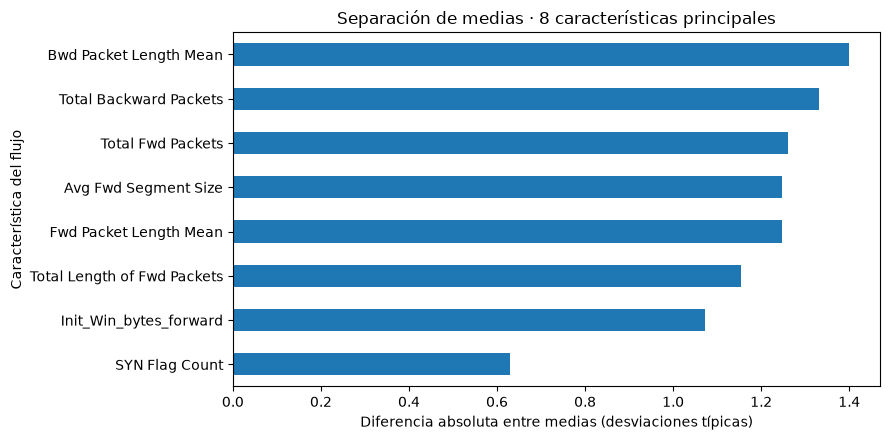

B.3 · Puertos más frecuentes y tasa de ataques dentro de cada puerto


,Total de flujos,Fracción de ataque
Destination Port,,
80.0,22411,0.601
443.0,18933,0.080
53.0,8933,0.000
22.0,2275,0.000
8080.0,2185,0.000
3389.0,845,0.000


In [11]:
# 'num' contiene las columnas numéricas identificadas antes de crear la etiqueta 'y'.
# Cada columna se centra por su media y se divide por su desviación; si std=0 usamos 1.
Z = (df[num] - df[num].mean()) / df[num].std().replace(0, 1)

# Selecciona cada clase y resta sus medias; abs descarta el signo y mide magnitud.
dif = (Z[df.y == 1].mean() - Z[df.y == 0].mean()).abs().sort_values(ascending=False)

print("=" * 66)
print("B.3 · Diferencia absoluta de medias estandarizadas")
print("=" * 66)
display(dif.head(8).rename("Diferencia |medias| (desviaciones típicas)").to_frame().round(3))

fig, ax = plt.subplots(figsize=(9, 4.5))
dif.head(8).plot.barh(ax=ax)
ax.invert_yaxis()  # La característica con mayor diferencia aparece arriba.
ax.set(title="Separación de medias · 8 características principales",
       xlabel="Diferencia absoluta entre medias (desviaciones típicas)",
       ylabel="Característica del flujo")
plt.tight_layout()
plt.show()

# P(ataque | puerto): porcentaje de ataques entre todos los flujos con ese puerto.
puertos = df.groupby("Destination Port").agg(
    n=("y", "size"), ataque=("y", "mean")
).sort_values("n", ascending=False).head(6)
print("B.3 · Puertos más frecuentes y tasa de ataques dentro de cada puerto")
display(puertos.rename(columns={"n": "Total de flujos", "ataque": "Fracción de ataque"}).round(3))

**Cómo interpretar la tabla de puertos:** la fila del puerto 80 contesta `P(ataque | puerto=80)`: **de todas las conexiones dirigidas al puerto 80**, ¿qué fracción son ataques? Eso es distinto de `P(puerto=80 | ataque)`: **de todos los ataques**, ¿qué fracción usa el puerto 80? En el generador se concentran artificialmente ataques en ese puerto; ese patrón **no es una propiedad general del HTTP**.

**Matiz estadístico:** incluso si dos clases comparten la misma media, pueden tener formas muy diferentes. Por ejemplo, `[-10,10]` y `[0,0]` tienen media 0 pero dispersión distinta. En consecuencia, la diferencia de medias es una pista exploratoria y no una demostración de utilidad predictiva.

### B.4 · Correlaciones y líneas temporales

La **correlación de Pearson** toma valores entre `−1` (relación lineal inversa perfecta) y `+1` (directa perfecta); un valor cercano a `0` indica que no hay una **relación lineal fuerte**, pero no descarta relaciones no lineales. **Correlación no implica causalidad.** En este generador, `Fwd Packet Length Mean` y `Avg Fwd Segment Size` se calculan con el mismo valor, por eso su correlación es 1. Mantener columnas redundantes puede aumentar coste y complicar la interpretación de pesos; no siempre perjudica a árboles.

La **línea temporal** resume cuántos flujos aparecen por minuto y clase (`0=benigno`, `1=ataque`). Para ello `set_index("Timestamp")` pone las fechas en el índice, `groupby("y")` separa las dos clases, `resample("1min")` reúne eventos de cada minuto, `size()` cuenta y `unstack(0)` produce una columna por clase. El gráfico muestra actividad **dentro del escenario sintético**, no una afirmación sobre un incidente real.

B.4 · Correlación entre variables numéricas
Correlación entre las dos columnas redundantes (generadas iguales): 1.000


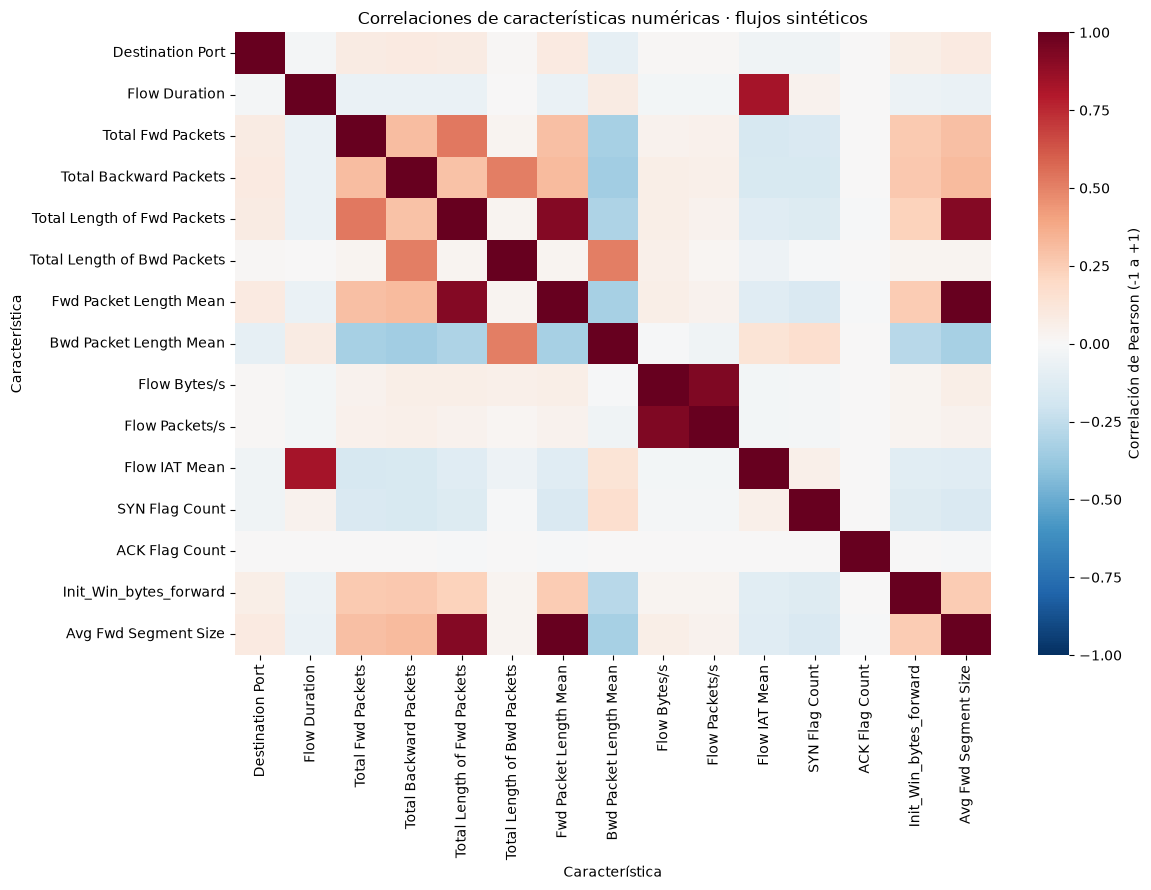

In [12]:
# Relación lineal entre pares de columnas numéricas; la diagonal de corr() es 1.
correlaciones = df[num].corr()
print("=" * 66)
print("B.4 · Correlación entre variables numéricas")
print("=" * 66)
par_redundante = correlaciones.loc["Fwd Packet Length Mean", "Avg Fwd Segment Size"]
print(f"Correlación entre las dos columnas redundantes (generadas iguales): {par_redundante:.3f}")

fig, ax = plt.subplots(figsize=(12, 9))
sns.heatmap(correlaciones.round(2), cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            ax=ax, cbar_kws={"label": "Correlación de Pearson (-1 a +1)"})
ax.set_title("Correlaciones de características numéricas · flujos sintéticos")
ax.set_xlabel("Característica")
ax.set_ylabel("Característica")
plt.tight_layout()
plt.show()

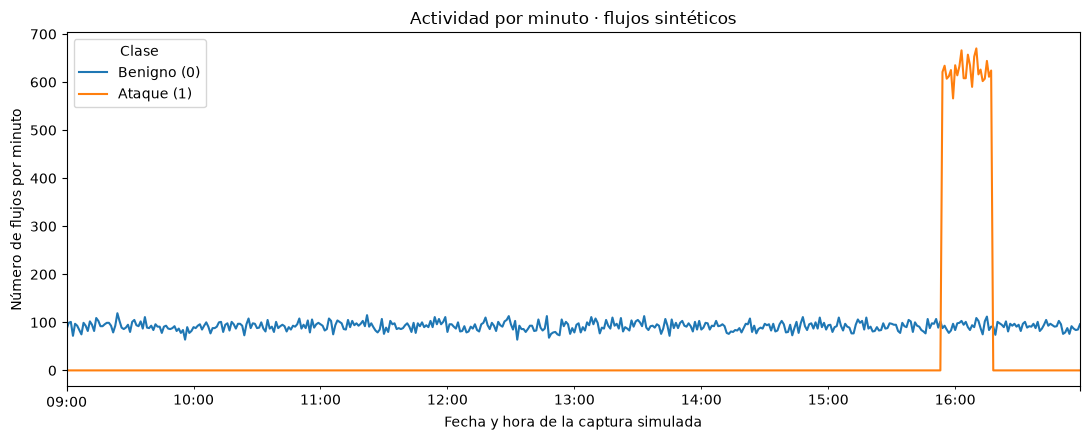

B.4 · Minuto con mayor número de ataques (dentro del escenario generado)
Momento: 2017-07-07 16:10:00 | Flujos de ataque en ese minuto: 670


In [13]:
# Convertir la columna temporal en índice permite agrupar en ventanas de un minuto.
serie = (df.set_index("Timestamp")
           .groupby("y")
           .resample("1min")
           .size()
           .unstack(0)
           .fillna(0))

# Misma información y cálculo originales; solo mejoramos el rotulado del gráfico.
fig, ax = plt.subplots(figsize=(11, 4.5))
serie.rename(columns={0: "Benigno (0)", 1: "Ataque (1)"}).plot(ax=ax)
ax.set(title="Actividad por minuto · flujos sintéticos",
       xlabel="Fecha y hora de la captura simulada", ylabel="Número de flujos por minuto")
ax.legend(title="Clase")
plt.tight_layout()
plt.show()

print("B.4 · Minuto con mayor número de ataques (dentro del escenario generado)")
if 1 in serie.columns:
    instante_pico = serie[1].idxmax()
    print(f"Momento: {instante_pico} | Flujos de ataque en ese minuto: {int(serie.loc[instante_pico, 1])}")

**Interpretación:** en este escenario, la gran concentración de ataques aparece alrededor de las **16:00** porque el generador los ubica cerca de esa hora. Ese pico **no demuestra** que «las cuatro de la tarde sea una hora peligrosa» en redes reales. Si ves dos columnas altamente correlacionadas, investiga si son duplicadas, si una aporta nueva información y si ambas estarán disponibles al desplegar el modelo; **no elimines una automáticamente**.

### B.5 · Reto opcional: ejecutar el análisis con un CSV real de CICIDS2017

**Enunciado original:** coloca `Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv` (distribución `MachineLearningCVE`) junto al notebook y repite perfilado y limpieza. Usaremos `usecols` para importar **solo seis columnas**, ahorrando memoria. Este bloque es opcional: si el archivo no existe, informa y continúa sin impedir el resto del curso.

Los nombres de columna del CSV original pueden contener espacios; la función `lambda col: col.strip() in columnas` permite seleccionar por su nombre normalizado. Se conservan las operaciones originales: reemplazar infinitos, eliminar filas con nulos, deduplicar y crear `y`. **No sustituimos el dataset real por uno inventado si falta el CSV.**

In [14]:
# Ejercicio opcional. Archivo oficial externo: el notebook no lo fabrica ni lo descarga.
ruta = "Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv"
columnas = ["Destination Port", "Flow Duration", "Total Fwd Packets",
            "Total Backward Packets", "Flow Bytes/s", "Label"]

try:
    real = pd.read_csv(
        ruta,
        usecols=lambda columna: columna.strip() in columnas,
        low_memory=False,
    )
    real.columns = real.columns.str.strip()
    recuento_original = len(real)

    print("=" * 66)
    print("B.5 · CSV REAL CICIDS2017 · Perfilado y limpieza")
    print("=" * 66)
    print(f"Archivo: {ruta} | Filas originales: {recuento_original:,} | Columnas: {len(real.columns)}")
    print("Distribución de etiquetas original:")
    display(real["Label"].value_counts().rename("N.º de flujos").to_frame())

    # Conservamos la secuencia de limpieza del ejercicio.
    real = real.replace([np.inf, -np.inf], np.nan)
    print("Nulos o infinitos (tras reemplazarlos) por columna:")
    display(real.isna().sum().rename("N.º de ausencias").to_frame())
    print(f"Filas duplicadas antes de limpiar: {int(real.duplicated().sum()):,}")
    real = real.dropna().drop_duplicates().reset_index(drop=True)
    real["y"] = (real["Label"] != "BENIGN").astype(int)

    print(f"Filas eliminadas: {recuento_original - len(real):,}")
    print(f"Filas conservadas: {len(real):,}")
    print(f"Ataques tras limpieza: {real['y'].sum():,}/{len(real):,} = {real['y'].mean():.2%}")
except FileNotFoundError:
    print("B.5 · Ejercicio opcional no ejecutado: falta el CSV real en el directorio de trabajo.")
    print(f"Archivo esperado: {ruta}")
    print("La parte B principal ya se ha realizado con datos sintéticos; las partes siguientes pueden continuar.")

B.5 · Ejercicio opcional no ejecutado: falta el CSV real en el directorio de trabajo.
Archivo esperado: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
La parte B principal ya se ha realizado con datos sintéticos; las partes siguientes pueden continuar.


**Respuesta al reto de datos reales:** la misma *técnica* de lectura y limpieza puede aplicarse a datos de una captura real, pero sus efectos no tienen por qué coincidir. Pueden variar familias de ataques, puertos, formatos, ratios de ausencia, proporciones y períodos. La limpieza también podría cambiar el equilibrio de clases, de modo que conviene comparar **antes y después por etiqueta**. Si el CSV contiene una columna distinta o una variante de formato, es necesario validar el esquema antes de utilizar el resultado. Nunca generalices un 25 % sintético ni una correlación artificial a una red corporativa.

---
## Parte C · scikit-learn: baseline, regresión logística y árbol

### C.1 · Una misma interfaz para modelos diferentes

**Objetivo:** saber cuándo un modelo predice algo útil y no limitarse a celebrar una cifra de exactitud. En esta parte usamos **NSL-KDD**, no los flujos sintéticos de la parte B.

Los objetos de scikit-learn suelen seguir la misma interfaz:

1. `.fit(X_entrenamiento, y_entrenamiento)` **aprende** con las características y etiquetas del conjunto de entrenamiento.
2. `.predict(X_prueba)` predice etiquetas **sin haber visto las respuestas** de prueba durante el ajuste.
3. `.score(X_prueba, y_prueba)` devuelve la **exactitud** (*accuracy*) para estos clasificadores: porcentaje de etiquetas acertadas.

`Xtr` son 12 características numéricas de **entrenamiento** y `ytr` sus etiquetas `0/1`; `Xte` son las mismas 12 características en **prueba** y `yte` sus etiquetas, utilizadas solo para evaluar. Los nombres son abreviaturas de *X train*, *y train*, *X test*, *y test*. Las características incluyen `duration` (duración), `src_bytes`/`dst_bytes` (bytes enviados/recibidos), varios contadores y tasas, y `logged_in` (indicador de sesión iniciada). Excluimos explícitamente `label`, `difficulty` e `is_attack` del conjunto de características.

**Los tres modelos originales:**

- **Baseline — `DummyClassifier(strategy="most_frequent")`:** no aprende patrones de tráfico; predice siempre la clase más frecuente **en entrenamiento**. Sirve como referencia mínima. Su exactitud en prueba puede diferir mucho de su exactitud de entrenamiento si cambia la proporción de clases.
- **Regresión logística:** combina características con pesos, calcula un valor y lo transforma en una probabilidad mediante una curva logística (*sigmoide*). `StandardScaler()` aprende media y desviación de **entrenamiento** para cada columna. `make_pipeline(escalador, modelo)` garantiza que al predecir se aplique la **misma transformación**, sin ajustar sobre prueba. `max_iter=1000` es un máximo de iteraciones del optimizador, no 1.000 modelos.
- **Árbol de decisión:** toma decisiones encadenadas como «si `duration` supera cierto umbral, ir por la rama derecha». `max_depth=6` limita el número de niveles de separación para reducir complejidad. `random_state=0` hace reproducibles las decisiones aleatorias que procedan.

**Exactitud:** si acertamos 80 de 100 observaciones, `accuracy = 80/100 = 0,80 = 80 %`. No distingue entre dejar pasar un ataque (**falso negativo**) y generar una alerta innecesaria (**falso positivo**). El baseline es esencial para juzgar el valor añadido; en detección de intrusiones también interesan *recall*, precisión y matriz de confusión, que se desarrollan en otras sesiones.

In [15]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# Las 12 columnas numéricas se mantienen exactamente como en el laboratorio original.
feats = [
    "duration", "src_bytes", "dst_bytes", "count", "srv_count", "serror_rate",
    "rerror_rate", "same_srv_rate", "diff_srv_rate", "dst_host_count",
    "dst_host_srv_count", "logged_in",
]

# Extraemos los mismos campos en los dos archivos NSL-KDD. La etiqueta se guarda aparte.
Xtr, ytr = tr[feats], tr.is_attack
Xte, yte = te[feats], te.is_attack

modelos_comparacion = [
    ("baseline", DummyClassifier(strategy="most_frequent")),
    ("logística", make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))),
    ("árbol", DecisionTreeClassifier(max_depth=6, random_state=0)),
]

# .score de un clasificador calcula accuracy = aciertos / total.
filas_metricas = []
for nombre, m in modelos_comparacion:
    m.fit(Xtr, ytr)  # Solo entrenamiento: no ajustamos nada con Xte o yte.
    filas_metricas.append({
        "Modelo": nombre,
        "Exactitud entrenamiento": m.score(Xtr, ytr),
        "Exactitud prueba": m.score(Xte, yte),
    })

comparacion_modelos = pd.DataFrame(filas_metricas)
print("=" * 66)
print("C.1 · Modelos NSL-KDD: mismo problema, distintos métodos")
print("=" * 66)
print(f"Entrenamiento: {Xtr.shape[0]:,} conexiones × {Xtr.shape[1]} características")
print(f"Prueba: {Xte.shape[0]:,} conexiones × {Xte.shape[1]} características")
print(f"Clase mayoritaria en entrenamiento: {int(ytr.mode().iloc[0])} (0=normal, 1=ataque)")
print(f"Porcentaje de ataques: entrenamiento {ytr.mean():.1%} | prueba {yte.mean():.1%}")
display(comparacion_modelos.round(4))
print("Lectura · 0.80 significa el 80 % de conexiones clasificadas correctamente.")

C.1 · Modelos NSL-KDD: mismo problema, distintos métodos
Entrenamiento: 125,973 conexiones × 12 características
Prueba: 22,544 conexiones × 12 características
Clase mayoritaria en entrenamiento: 0 (0=normal, 1=ataque)
Porcentaje de ataques: entrenamiento 46.5% | prueba 56.9%


,Modelo,Exactitud entrenamiento,Exactitud prueba
0,baseline,0.5346,0.4308
1,logística,0.9070,0.7323
2,árbol,0.9770,0.7782


Lectura · 0.80 significa el 80 % de conexiones clasificadas correctamente.


**Interpretación sin inventar resultados:** observa la columna **Exactitud prueba**, no solo la de entrenamiento. La referencia del original mencionaba alrededor de **43 %** para el baseline en prueba; ese porcentaje depende de qué clase sea mayoritaria en el **entrenamiento** y de su frecuencia real en **prueba**. La tabla ejecutada contiene el dato verificable para tus archivos. Si un modelo acierta mucho en entrenamiento y bastante menos en prueba, puede estar ajustándose a patrones poco generalizables (*sobreajuste*). Si un baseline es competitivo, debes analizar si el problema está muy desequilibrado y si la exactitud oculta ataques sin detectar.

### C.2 · Regresión logística: coeficientes y probabilidades

La regresión logística binaria forma una puntuación a partir de características estandarizadas `z₁ ... z₁₂` y pesos aprendidos `w₁ ... w₁₂`:

$$s=w_0 + w_1 z_1 + w_2 z_2 + \cdots + w_{12} z_{12},\qquad P(ataque)=\frac{1}{1+e^{-s}}.$$

`w₀` es el término independiente (*intercepto*). Si la puntuación aumenta, la probabilidad prevista para la clase **1 (ataque)** aumenta. Un peso positivo sugiere asociación **condicional a los otros predictores del modelo**; un peso negativo, lo contrario. No demuestra causalidad ni que esa variable funcione por sí sola. Los pesos pueden ser inestables si hay variables muy correlacionadas.

`predict_proba(Xte)` devuelve **una fila por observación** y **una columna por clase**. Como `classes_=[0,1]`, la primera es `P(normal)` y la segunda `P(ataque)`; **suman 1**. Por ejemplo, `[0.15, 0.85]` representa 15 % de probabilidad estimada de normal y 85 % de ataque. No significa que el modelo acierte el 85 % de las veces, ni garantiza que las probabilidades estén calibradas.

Para aislar la interpretación, el laboratorio vuelve a entrenar explícitamente **la misma regresión logística** con los mismos datos y parámetros que en C.1.

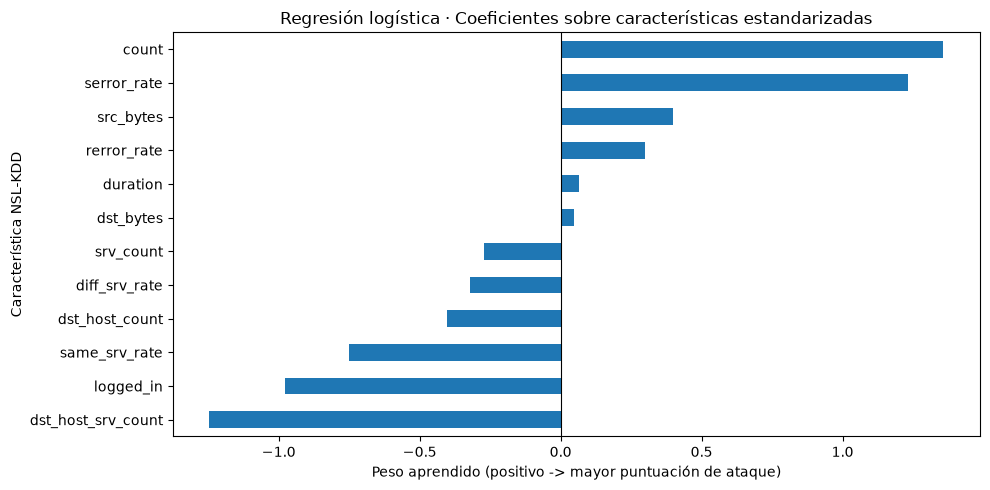

C.2 · Predicciones probabilísticas de cinco conexiones de prueba


,Etiqueta real (0/1),Predicción (0/1),P(clase 0),P(clase 1)
0,1,1,0.008,0.992
1,1,1,0.020,0.980
2,0,0,0.667,0.333
3,1,0,0.519,0.481
4,1,1,0.347,0.653


Lectura · P(clase 0) = P(normal); P(clase 1) = P(ataque).
Comprobación · Ambas probabilidades de cada fila suman 1 (salvo redondeo).


In [16]:
# Mismo pipeline logístico que en la comparación anterior; se conserva como 'log'.
log = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(Xtr, ytr)

# coef_[0] = peso aprendido para cada una de las 12 características.
# Solo tienen sentido en relación con la clase positiva (1 = ataque).
pesos = pd.Series(log[-1].coef_[0], index=feats).sort_values()
fig, ax = plt.subplots(figsize=(10, 5))
pesos.plot.barh(ax=ax)
ax.axvline(0, color="black", linewidth=0.8)
ax.set(title="Regresión logística · Coeficientes sobre características estandarizadas",
       xlabel="Peso aprendido (positivo -> mayor puntuación de ataque)",
       ylabel="Característica NSL-KDD")
plt.tight_layout()
plt.show()

# Para cada una de las cinco primeras conexiones: P(clase 0) y P(clase 1).
probabilidades = log.predict_proba(Xte)[:5].round(3)
tabla_probabilidades = pd.DataFrame(
    probabilidades,
    columns=[f"P(clase {clase})" for clase in log[-1].classes_],
)
tabla_probabilidades.insert(0, "Etiqueta real (0/1)", yte.iloc[:5].to_numpy())
tabla_probabilidades.insert(1, "Predicción (0/1)", log.predict(Xte.iloc[:5]))

print("=" * 66)
print("C.2 · Predicciones probabilísticas de cinco conexiones de prueba")
print("=" * 66)
display(tabla_probabilidades)
print("Lectura · P(clase 0) = P(normal); P(clase 1) = P(ataque).")
print("Comprobación · Ambas probabilidades de cada fila suman 1 (salvo redondeo).")

**Qué conclusiones puedes extraer:** el gráfico muestra **qué coeficientes ha aprendido este modelo concreto**; no es un ranking universal de causas de intrusión. Compara las dos probabilidades de cada fila y después la etiqueta real. Una conexión prevista como ataque puede ser un falso positivo y una prevista como normal puede ser un falso negativo. El umbral usado por `.predict` es el predeterminado; en producción podríamos elegirlo en función del coste de cada error, pero ese ajuste requeriría datos de validación separados.

### C.3 · Reto resuelto: bosque aleatorio y datos sintéticos

**Enunciado original:** sustituye la regresión logística por `RandomForestClassifier(n_estimators=100, random_state=0)` **cambiando una sola línea** dentro del pipeline y compárala. Después repite la división y los modelos sobre la parte B usando `train_test_split(..., stratify=df.y, test_size=0.3, random_state=0)`. ¿Por qué puede aparecer una exactitud casi perfecta y por qué no debemos extrapolarla?

Un **Random Forest** entrena numerosos árboles de decisión con variaciones en los datos y características; sus predicciones agregadas suelen ser menos sensibles que las de un único árbol. `n_estimators=100` fija **100 árboles**. En la primera comparación dejamos intactos el escalador, las 12 características y los archivos NSL-KDD: la sustitución conceptual consiste exactamente en cambiar `LogisticRegression(...)` por `RandomForestClassifier(...)`.

Al trabajar con el dataset sintético, **no incluimos `Label` ni `y` como entradas**, porque contienen la respuesta; tampoco `Timestamp`, que es una fecha y podría codificar artificialmente el horario del ataque. Para evitar mezclar clases de forma accidental, `stratify=df.y` intenta mantener la proporción de benignos y ataques en la división 70 % entrenamiento / 30 % prueba. La división sigue siendo **aleatoria**, no temporal.

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

# 1) NSL-KDD: cambiar SOLO el estimador dentro de este pipeline.
bosque_nsl = make_pipeline(
    StandardScaler(), RandomForestClassifier(n_estimators=100, random_state=0)
)
bosque_nsl.fit(Xtr, ytr)

print("=" * 66)
print("C.3 · Reto 1: bosque aleatorio frente a logística en NSL-KDD")
print("=" * 66)
display(pd.DataFrame({
    "Modelo": ["Regresión logística", "Bosque aleatorio (100 árboles)"],
    "Exactitud entrenamiento": [log.score(Xtr, ytr), bosque_nsl.score(Xtr, ytr)],
    "Exactitud prueba": [log.score(Xte, yte), bosque_nsl.score(Xte, yte)],
}).round(4))

# 2) Datos sintéticos: únicamente columnas predictoras numéricas.
# 'y' es nuestra etiqueta; 'Label' es el texto equivalente; ninguna entra en X.
columnas_flujos = df.select_dtypes("number").columns.drop("y")
X_flujos = df[columnas_flujos]
y_flujos = df["y"]

X_flujos_train, X_flujos_test, y_flujos_train, y_flujos_test = train_test_split(
    X_flujos, y_flujos,
    stratify=df.y, test_size=0.3, random_state=0,
)

# Comparamos los mismos tipos de modelos del bloque C en un segundo dataset.
modelos_flujos = [
    ("baseline", DummyClassifier(strategy="most_frequent")),
    ("logística", make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))),
    ("bosque", make_pipeline(StandardScaler(), RandomForestClassifier(n_estimators=100, random_state=0))),
]
resultados_flujos = []
for nombre, modelo_flujos in modelos_flujos:
    modelo_flujos.fit(X_flujos_train, y_flujos_train)
    resultados_flujos.append({
        "Modelo": nombre,
        "Exactitud entrenamiento": modelo_flujos.score(X_flujos_train, y_flujos_train),
        "Exactitud prueba": modelo_flujos.score(X_flujos_test, y_flujos_test),
    })

print("\nC.3 · Reto 2: comparar modelos con datos sintéticos del bloque B")
print(f"Filas de entrenamiento: {len(X_flujos_train):,}; filas de prueba: {len(X_flujos_test):,}")
print(f"Características utilizadas: {len(columnas_flujos)} numéricas (sin y/Label/Timestamp)")
print(f"Ataques: entrenamiento={y_flujos_train.mean():.1%}, prueba={y_flujos_test.mean():.1%}")
display(pd.DataFrame(resultados_flujos).round(4))

**Respuesta al reto (por qué casi perfecto ≠ detector listo para producción):** el generador asignó a los ataques reglas deliberadamente regulares: tiempos concentrados, determinados puertos, tamaños y ventanas TCP distintos de los benignos. Al separar **aleatoriamente** filas del mismo generador, entrenamiento y prueba siguen procediendo de patrones muy parecidos. Un árbol o un bosque puede memorizar con facilidad las fronteras creadas en ese escenario y obtener resultados enormes sin aprender a reconocer ataques nuevos. Además, el conjunto sintético ya pasó por una limpieza específica conocida. Eso **no prueba** cómo funcionará ante herramientas distintas, deriva temporal, otros protocolos, datos corruptos o clases nuevas. La evaluación NSL-KDD y la sintética responden a preguntas diferentes y **no se deben comparar sus porcentajes como si fueran el mismo examen**.

---
## Parte D · k-NN desde cero: implementar y verificar un algoritmo

### D.1 · «Dime quiénes son tus vecinos»

El algoritmo **k-nearest neighbors (k-NN)** predice una observación nueva mirando las **`k` observaciones de entrenamiento más cercanas** en el espacio de características. Con `k=5`, si de los cinco vecinos tres son ataques (`1`) y dos benignos (`0`), predice **ataque**. Es un algoritmo supervisado porque esos vecinos **ya tienen etiqueta**.

A diferencia de la regresión logística, k-NN no ajusta pesos para una frontera durante `.fit`: principalmente **almacena los ejemplos**. El trabajo costoso ocurre al predecir, cuando tiene que buscar vecinos. Por ello, aumentar mucho los datos de entrenamiento puede hacer la predicción más lenta.

**Entradas concretas del ejercicio:** extraemos aleatoriamente, con semilla 0, **5.000 flujos de entrenamiento** (`i_tr`) y **1.000 de prueba** (`i_te`) de NSL-KDD. `StandardScaler().fit(Xtr.iloc[i_tr])` aprende las medias y desviaciones **solo del subconjunto de entrenamiento**. `A` y `B` son matrices escaladas de tamaño `(5000,12)` y `(1000,12)`; `ya` y `yb` son sus etiquetas verdaderas.

Para calcular distancias sin un bucle por cada par, utilizamos la identidad de la parte A:

$$d^2(b,a)=\lVert b\rVert^2+\lVert a\rVert^2-2\,b\cdot a.$$

No hace falta sacar la raíz: **el vecino con menor distancia al cuadrado también tiene menor distancia**. `np.argpartition(..., k, axis=1)[:, :k]` devuelve los índices de los k valores más pequeños **sin ordenarlos internamente**, más barato que ordenar todas las distancias. `ya[vecinos].mean(axis=1) > 0.5` hace una **votación** de etiquetas binarias: con `k=5` no hay empate exacto entre 0 y 1. Al final comparamos nuestra implementación con la clase equivalente de scikit-learn.

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

# Muestras originales: 5000 observaciones conocidas y 1000 desconocidas.
rng = np.random.default_rng(0)
i_tr = rng.choice(len(Xtr), 5000, replace=False)
i_te = rng.choice(len(Xte), 1000, replace=False)

# Se aprende el escalado exclusivamente de los datos de entrenamiento muestreados.
sc = StandardScaler().fit(Xtr.iloc[i_tr])
A = sc.transform(Xtr.iloc[i_tr])
B = sc.transform(Xte.iloc[i_te])
ya = ytr.iloc[i_tr].to_numpy()
yb = yte.iloc[i_te].to_numpy()


def knn_predict(A, ya, B, k=5):
    """Predice 0/1 por mayoría entre los k vecinos más próximos, usando distancias al cuadrado.

    A: matriz de entrenamiento (filas = conexiones, columnas = características).
    ya: etiquetas 0/1 de esas filas, con el mismo orden de A.
    B: conexiones nuevas con las mismas características y la misma escala que A.
    k: número de vecinos cuyo voto decide cada resultado (por defecto 5).
    """
    # Formas: (n_test,1) + (1,n_train) - (n_test,n_train).
    # Cada celda contiene la distancia euclídea AL CUADRADO de una pareja B-A.
    d2 = ((B ** 2).sum(1)[:, None]
          + (A ** 2).sum(1)[None, :]
          - 2 * B @ A.T)

    # Para cada fila de prueba, selecciona los k vecinos con menor distancia.
    vecinos = np.argpartition(d2, k, axis=1)[:, :k]

    # Porcentaje de vecinos con etiqueta 1; mayoría estricta (> 50 %) => 1.
    return (ya[vecinos].mean(axis=1) > 0.5).astype(int)


# Dos implementaciones diferentes sobre los MISMOS ejemplos estandarizados.
p_mio = knn_predict(A, ya, B)
p_sk = KNeighborsClassifier(n_neighbors=5).fit(A, ya).predict(B)

coincidencia = (p_mio == p_sk).mean()
exactitud_propia = (p_mio == yb).mean()
exactitud_sklearn = (p_sk == yb).mean()

print("=" * 66)
print("D.1 · k-NN manual frente a scikit-learn")
print("=" * 66)
print(f"Entrenamiento A: {A.shape} | Etiquetas ya: {ya.shape}")
print(f"Prueba B: {B.shape} | Etiquetas verdaderas yb: {yb.shape}")
display(pd.DataFrame({
    "Métrica": ["Coincidencia entre las dos implementaciones", "Exactitud k-NN manual en prueba",
               "Exactitud k-NN scikit-learn en prueba", "Predicciones distintas entre implementaciones"],
    "Valor": [f"{coincidencia:.2%}", f"{exactitud_propia:.2%}",
              f"{exactitud_sklearn:.2%}", int((p_mio != p_sk).sum())],
}))
print("Ejemplo · Diez primeras etiquetas de prueba, predicción manual y predicción de biblioteca:")
display(pd.DataFrame({
    "Etiqueta real": yb[:10],
    "k-NN manual": p_mio[:10],
    "k-NN scikit-learn": p_sk[:10],
}))

**Interpretación:** «coincidencia del 99 %» significaría que los dos programas dieron la **misma predicción en 990 de 1.000 casos**, independientemente de si esa predicción era correcta. La **exactitud** es otra medida: compara la predicción con `yb`, la etiqueta real de esos 1.000 casos. Por tanto, **coincidir mucho con scikit-learn no demuestra que el detector sea bueno**; solo valida que nuestra implementación reproduce casi siempre sus decisiones. Las diferencias raras pueden aparecer por empates entre vecinos, detalles de precisión numérica o reglas de desempate; no deben ocultarse.

### D.2 · Reto resuelto: sin escalado y con 5.000 / 50.000 vecinos potenciales

**Enunciado original:** elimina el escalado y calcula la exactitud. Después compara el tiempo de predicción con **5.000 y 50.000 filas de entrenamiento** y explica su complejidad `O(n_train × n_test)`.

**Por qué importa la escala:** imagina que una diferencia de `1.000` en `src_bytes` aporta `1.000² = 1.000.000` al cuadrado de la distancia, mientras que una tasa que cambia de `0,2` a `0,9` aporta `(0,7)² = 0,49`. El algoritmo prácticamente ignoraría la tasa, aunque esta pudiese ser importante. No hay garantía de que `src_bytes` sea **siempre** la variable dominante: la importancia real depende de los rangos del dataset; el reto sirve para medir el efecto.

**Diseño de la medición de tiempo:** mantendremos **100 conexiones de prueba fijas** para comparar velocidades sin consumir cientos de MB en una matriz innecesariamente grande. El experimento principal D.1 **sigue usando 1.000** conexiones; reducir el tamaño aquí afecta **solo al benchmark opcional**. En ambos tiempos usamos el **mismo escalador ajustado al subconjunto de 50.000 datos de entrenamiento**; así comparamos principalmente el coste de 5.000 frente a 50.000 distancias por consulta.

In [ ]:
# 1) SIN escalar: mismas 5000/1000 filas originales, pero con valores crudos.
A_crudo = Xtr.iloc[i_tr].to_numpy()
B_crudo = Xte.iloc[i_te].to_numpy()
pred_crudo = knn_predict(A_crudo, ya, B_crudo)

print("=" * 66)
print("D.2 · Efecto de no estandarizar las características")
print("=" * 66)
display(pd.DataFrame({
    "Configuración": ["k-NN con escalado", "k-NN sin escalado"],
    "Exactitud en las mismas 1000 filas de prueba": [exactitud_propia, (pred_crudo == yb).mean()],
}).round(4))
print(f"Predicciones que cambian al quitar el escalado: {int((pred_crudo != p_mio).sum())} de {len(yb)}")

# 2) TIEMPOS: el número de consultas se mantiene fijo en 100 para contener memoria.
# El conjunto de entrenamiento mayor contiene 50.000 filas, sin reemplazo.
rng_tiempos = np.random.default_rng(0)
indice_50000 = rng_tiempos.choice(len(Xtr), 50_000, replace=False)
indice_5000 = indice_50000[:5_000]  # Subconjunto anidado: compara tamaños sobre la misma distribución.

escalador_benchmark = StandardScaler().fit(Xtr.iloc[indice_50000])
B_benchmark = escalador_benchmark.transform(Xte.iloc[i_te[:100]])
A_benchmark_5000 = escalador_benchmark.transform(Xtr.iloc[indice_5000])
A_benchmark_50000 = escalador_benchmark.transform(Xtr.iloc[indice_50000])

resultados_tiempos = []
for etiqueta, datos_train_knn, indices_train in [
    ("5.000 vecinos posibles", A_benchmark_5000, indice_5000),
    ("50.000 vecinos posibles", A_benchmark_50000, indice_50000),
]:
    inicio = time.perf_counter()
    predicciones_benchmark = knn_predict(
        datos_train_knn, ytr.iloc[indices_train].to_numpy(), B_benchmark
    )
    duracion = time.perf_counter() - inicio
    resultados_tiempos.append({
        "Entrenamiento": etiqueta,
        "Consultas (prueba)": len(B_benchmark),
        "Pares de distancias": len(datos_train_knn) * len(B_benchmark),
        "Tiempo de predicción (s)": duracion,
    })

print("\nD.2 · Coste de predecir 100 flujos (misma prueba, escala y algoritmo)")
display(pd.DataFrame(resultados_tiempos).round(4))
print("Interpretación · Multiplicar el entrenamiento por 10 multiplica por 10 los pares que hay que comparar.")

**Respuesta al reto:** la complejidad de calcular distancias de k-NN es del orden de `n_train × n_test × número_de_características`. Aquí hay **12 características fijas**, así que se resume como `O(n_train × n_test)`. Con 100 consultas, pasar de 5.000 a 50.000 filas cambia de **500.000** a **5.000.000** parejas de distancias. El tiempo observado **no necesariamente será exactamente diez veces mayor**: NumPy usa bibliotecas optimizadas y hay costes fijos, memoria y cachés. La exactitud sin escalado puede subir o bajar; lo importante es comprender que ahora las características tienen pesos implícitos determinados por sus unidades. El ajuste del escalado sobre prueba sería una fuga, por eso se ajusta solo con entrenamiento.

---
## Parte E · Guardar y servir un modelo con joblib

### E.1 · De un objeto entrenado a predicciones sobre un archivo nuevo

**Objetivo:** demostrar que un modelo no vive únicamente dentro de una celda. Cuando lo entrenamos, el objeto Python conserva lo aprendido: aquí, la normalización y los árboles de un bosque aleatorio. Con `joblib.dump()` podemos **serializarlo** (guardarlo en disco) y más tarde con `joblib.load()` **recuperarlo** para predecir.

El modelo original utiliza `make_pipeline(StandardScaler(), RandomForestClassifier(n_estimators=150, random_state=0, n_jobs=-1))`. Los **150 árboles** pertenecen al bosque; `n_jobs=-1` intenta emplear todos los núcleos disponibles durante operaciones que admiten paralelización. **No hay que recalcular ni reajustar las medias con cada CSV nuevo:** el `StandardScaler` ya está entrenado dentro del pipeline.

El archivo **`ids_basico.joblib`** guarda tres elementos: `modelo` (pipeline entrenado), `features` (los doce nombres de columnas y su orden) y `version_sklearn` (versión con la que se serializó). **`muestra.csv`** contiene las primeras diez filas de prueba de NSL-KDD, solo con esas doce características; deliberadamente no se guarda su etiqueta `is_attack` dentro del CSV de entrada, porque el servicio debería predecirla.

La función `puntuar(fichero_csv)` abre ese CSV, **reordena las columnas por nombre**, carga el modelo y devuelve una `Series` de probabilidades de clase **1 (ataque)**: por ejemplo, `0,92` representa una probabilidad estimada de 92 %, no una alarma definitiva. **Seguridad:** un `.joblib`/pickle de origen desconocido puede ejecutar código al cargarse; carga únicamente artefactos propios o confiables y validados. Guardar la versión ayuda a detectar incompatibilidades, pero **no garantiza** que un archivo funcione sin problemas entre versiones.

In [ ]:
import joblib

# Exacto algoritmo original: 150 árboles, semilla 0 y paralelización habilitada.
modelo = make_pipeline(
    StandardScaler(),
    RandomForestClassifier(n_estimators=150, random_state=0, n_jobs=-1),
).fit(Xtr, ytr)

# Serializar modelo + orden de columnas + versión de la biblioteca.
joblib.dump(
    {"modelo": modelo, "features": feats, "version_sklearn": sklearn.__version__},
    "ids_basico.joblib",
)


def puntuar(fichero_csv):
    """Devuelve P(ataque) por fila de un CSV con las 12 columnas del modelo.

    El archivo ids_basico.joblib debe haber sido generado con código propio/confiable.
    No entrena de nuevo: reutiliza el pipeline y el orden de características guardados.
    """
    paq = joblib.load("ids_basico.joblib")
    nuevos = pd.read_csv(fichero_csv)
    # Seleccionar por nombres hace que el orden físico de columnas del CSV sea irrelevante.
    entradas_ordenadas = nuevos[paq["features"]]
    return pd.Series(
        paq["modelo"].predict_proba(entradas_ordenadas)[:, 1], name="p_ataque"
    )


# Simular una entrada futura: diez conexiones de prueba SIN su etiqueta verdadera.
te[feats].head(10).to_csv("muestra.csv", index=False)
probabilidades_archivo = puntuar("muestra.csv")

print("=" * 66)
print("E.1 · Guardar el modelo y puntuar diez conexiones nuevas")
print("=" * 66)
print(f"Modelo: {Path('ids_basico.joblib').resolve()}")
print(f"Tamaño del artefacto: {Path('ids_basico.joblib').stat().st_size / 1e6:.2f} MB")
print(f"CSV de entrada: {Path('muestra.csv').resolve()}")
print(f"Características requeridas: {len(feats)} (en el orden guardado en el artefacto)")

# Solo para interpretar el resultado, mostramos también las etiquetas de prueba ya conocidas.
# Estas etiquetas NO han formado parte del CSV de entrada ni del entrenamiento del modelo.
tabla_inferencia = pd.DataFrame({
    "Conexión de prueba": np.arange(1, len(probabilidades_archivo) + 1),
    "Probabilidad estimada de ataque": probabilidades_archivo.round(3).to_numpy(),
    "Etiqueta real de referencia (0/1)": yte.iloc[:10].to_numpy(),
})
display(tabla_inferencia)

**Cómo se utiliza realmente:** al ejecutar E.1 se crean dos archivos junto al notebook. En otra sesión de Python con las bibliotecas adecuadas y un `ids_basico.joblib` **de confianza**, basta con cargar el artefacto y leer un CSV que contenga las características esperadas. En una aplicación podría llamar a esta función cada vez que llegue un flujo **con las mismas unidades y definiciones**; la salida es una probabilidad por conexión. Faltaría diseñar cómo se extraen los 12 atributos de paquetes reales, validar entradas y seleccionar umbrales de alerta. **Un modelo NSL-KDD no se conecta directamente a paquetes sin ese procesamiento previo.**

### E.2 · Reto resuelto: invertir el orden de las columnas

**Enunciado original:** guarda un `muestra.csv` con las columnas en orden inverso y confirma que `puntuar()` no cambia las probabilidades. ¿Qué pasaría si se pasara `nuevos.to_numpy()` directamente a `predict_proba()`?

La respuesta depende de cómo se entreguen los datos: un array `to_numpy()` **no contiene nombres de columnas**, solo su posición. Si se invierte el CSV, la primera columna que antes era `duration` podría pasar a ser `logged_in`, y el modelo interpretaría cada número como una característica **distinta** de aquella con la que aprendió. Puede producir predicciones incorrectas, además de advertencias de scikit-learn. Usar `nuevos[paq["features"]]` reconstruye el orden esperado antes de predecir.

In [ ]:
# Creamos OTRO CSV para conservar intacta la muestra original del ejercicio.
muestra_orden_inverso = "muestra_columnas_invertidas.csv"
datos_muestra = pd.read_csv("muestra.csv")
datos_muestra[feats[::-1]].to_csv(muestra_orden_inverso, index=False)

# Ambos CSV reciben exactamente las mismas probabilidades porque puntuar ordena por nombre.
p_original = puntuar("muestra.csv")
p_invertido = puntuar(muestra_orden_inverso)
coinciden_probabilidades = np.allclose(p_original, p_invertido)

print("=" * 66)
print("E.2 · Robustez al orden de columnas")
print("=" * 66)
print("Primera columna original:", datos_muestra.columns[0])
print("Primera columna en archivo invertido:", pd.read_csv(muestra_orden_inverso, nrows=0).columns[0])
display(pd.DataFrame({
    "P(ataque) · columnas originales": p_original.round(4),
    "P(ataque) · columnas invertidas": p_invertido.round(4),
    "Diferencia absoluta": (p_original - p_invertido).abs().round(10),
}))
print(f"¿Coinciden al reordenar por nombres? {coinciden_probabilidades}")
assert coinciden_probabilidades, "El cambio de orden del CSV no debería modificar las probabilidades."

**Respuesta:** la coincidencia demuestra que el sistema es robusto **al orden de las columnas de entrada**, no a columnas ausentes, atributos nuevos con nombres inesperados, unidades diferentes ni datos maliciosos. `nuevos.to_numpy()` directamente eliminaría la garantía de orden; aunque algún modelo siguiera ejecutándose, podría evaluar las entradas equivocadas. Si el CSV carece de una característica esperada, pandas generará un error de columna faltante, lo cual es preferible a una predicción silenciosamente incorrecta.

---
## Parte F · Ampliación: de registros de autenticación a un detector de anomalías

### F.1 · Convertir intentos de autenticación en ventanas de diez minutos

**Objetivo:** pasar de eventos aislados («un usuario se autenticó o falló») a una representación resumida que permita ver actividad inusual. Este bloque sigue siendo **sintético**, no contiene cuentas o IP reales.

Se generan **100.000 intentos** durante siete días con 200 usuarios y direcciones privadas aleatorias. Cada intento tiene `t` (fecha), `user` (usuario), `ip` (origen) y `ok` (`True` si autenticó correctamente). Se añaden otros **300 intentos fallidos deliberados**, del usuario **`u007`** y la IP **`10.10.10.44`**, entre **03:00 y 03:10 del 7 de enero de 2026**. Por tanto, la tabla final contiene **100.300 registros**.

El generador usa probabilidades: los intentos normales fallan aproximadamente un **5 %** de las veces, pero las cifras concretas dependen de la semilla 3. El procedimiento original resume por **usuario y ventana de 10 minutos**:

- `intentos`: número total de eventos en la ventana.
- `fallos`: número de eventos con `ok=False`.
- `ips`: direcciones IP de origen **distintas** durante la ventana.
- `tasa_fallo = fallos/intentos`: fracción de autenticaciones que han fallado, entre 0 y 1. Por ejemplo, `2/5=0,4` equivale a 40 %.

`groupby("user").resample("10min")` crea una ventana por usuario; **no** agrupa únicamente la IP del atacante. Primero hay que entender esta unidad de análisis, porque los modelos de la siguiente sección predecirán si **una ventana de un usuario** resulta extraña, no si una línea individual del log es maliciosa.

In [ ]:
# Datos y distribuciones conservados exactamente del original.
rng = np.random.default_rng(3)
n = 100_000
logs = pd.DataFrame({
    "t": (pd.to_datetime("2026-01-05")
          + pd.to_timedelta(rng.integers(0, 7 * 86400, n), unit="s")),
    "user": rng.choice([f"u{i:03d}" for i in range(200)], n),
    "ip": rng.choice([f"10.10.10.{i}" for i in range(2, 60)], n),
    "ok": rng.random(n) > 0.05,
})

# Evento malicioso inyectado: 300 fallos contra u007 dentro de 10 minutos.
rafaga = pd.DataFrame({
    "t": (pd.Timestamp("2026-01-07 03:00")
          + pd.to_timedelta(rng.integers(0, 600, 300), unit="s")),
    "user": "u007",
    "ip": "10.10.10.44",
    "ok": False,
})

# Concatenar y ordenar en el tiempo no altera la identidad de los eventos.
logs = pd.concat([logs, rafaga], ignore_index=True).sort_values("t")
logs["fallo"] = ~logs["ok"]  # Negación booleana: autenticación NO exitosa.

# El tiempo pasa al índice para poder agrupar en intervalos de 10 minutos.
v = (logs.set_index("t").groupby("user").resample("10min")
       .agg(intentos=("ok", "size"),
            fallos=("fallo", "sum"),
            ips=("ip", "nunique"))
       .reset_index())
v = v[v.intentos > 0].copy()  # No podemos dividir por cero en ventanas vacías.
v["tasa_fallo"] = v.fallos / v.intentos

print("=" * 66)
print("F.1 · Registro SSH sintético resumido por usuario y 10 minutos")
print("=" * 66)
print(f"Intentos simulados originales: {n:,}")
print(f"Intentos fallidos inyectados: {len(rafaga):,}")
print(f"Total de eventos: {len(logs):,} | Ventanas con actividad: {len(v):,}")
print("Cinco ventanas con más fallos de autenticación:")
display(v.sort_values("fallos", ascending=False).head(5).rename(columns={
    "user": "Usuario", "t": "Inicio de ventana", "intentos": "Intentos",
    "fallos": "Fallos", "ips": "IP distintas", "tasa_fallo": "Tasa de fallos",
}).round(3))

**Interpretación:** una ventana de `u007` en torno a las **03:00** concentra los 300 fallos inyectados (y podría incluir algún intento normal coincidente). Es la **anomalía esperada por diseño**. Una tasa de fallo del 100 % por sí sola no basta para acusar a un usuario: una ventana con **un solo intento fallido** también tiene tasa 100 %. Por eso combinamos volumen (`intentos`), fallos, número de IP y proporción de fallos.

### F.2 · Reto resuelto: Isolation Forest frente a reglas de umbral

**Enunciado original:** aplica `IsolationForest(contamination=0.001, random_state=0)` a `[intentos, fallos, ips, tasa_fallo]`; comprueba si la ventana de `u007` está entre las más anómalas y compara sus **falsos positivos** con una regla de umbral.

**Isolation Forest** no necesita etiquetas de ataque para ajustarse. Construye muchos árboles que separan puntos aleatoriamente; una observación muy distinta del resto suele quedar aislada tras **pocas particiones**, de modo que recibe una puntuación de anomalía más alta (o un `decision_function` más bajo). `contamination=0.001` indica una proporción esperada de anomalías **de alrededor del 0,1 %** y se usa para fijar un umbral interno: **no significa** que el detector haya demostrado que un 0,1 % de las ventanas sean maliciosas. `predict` devuelve `-1` para anomalía y `+1` para normalidad. No hay entrenamiento supervisado con la respuesta del ataque inyectado.

La **regla de umbral** será `fallos >= 10` por usuario/10 minutos. Una regla así es fácil de explicar, pero depende de elegir un umbral apropiado para el contexto. Para comparar falsas alarmas del ejercicio, aprovechamos una **verdad conocida por construcción**: la única ventana que contiene la ráfaga inyectada es la de `u007`, desde `2026-01-07 03:00` hasta `03:10`. Esto **no es una verdad de producción**; hemos creado nosotros el ataque.

Para cada método:

- **Verdadero positivo (VP):** alertó sobre la ventana inyectada.
- **Falso positivo (FP):** alertó sobre otra ventana, que este experimento considera benigna.
- **Falso negativo (FN):** no alertó sobre la ventana inyectada.
- **Verdadero negativo (VN):** no alertó sobre otra ventana.

La *precisión* de alertas, cuando hay alguna, es `VP/(VP+FP)`, y el *recall* de ataques inyectados es `VP/(VP+FN)`. Con **un único episodio de ataque**, estas cifras sirven para **entender el experimento**, no para declarar que un método es superior en general.

In [ ]:
from sklearn.ensemble import IsolationForest

columnas_anomalia = ["intentos", "fallos", "ips", "tasa_fallo"]

# Modelo no supervisado: solo recibe características, NO la verdad de la inyección.
isolation_forest = IsolationForest(contamination=0.001, random_state=0)
isolation_forest.fit(v[columnas_anomalia])

# -1 significa anomalía; decision_function más bajo => más anómalo.
v["alerta_isolation"] = isolation_forest.predict(v[columnas_anomalia]) == -1
v["puntuacion_isolation"] = isolation_forest.decision_function(v[columnas_anomalia])

# Regla explícita de conteo de fallos (no depende de entrenamiento).
v["alerta_umbral"] = v["fallos"] >= 10

# Identificador de la única ventana realmente inyectada en el experimento.
instante_inyeccion = pd.Timestamp("2026-01-07 03:00:00")
v["verdad_inyectada"] = (v["user"].eq("u007") & v["t"].eq(instante_inyeccion))
assert v["verdad_inyectada"].sum() == 1, "El ejercicio debe localizar una ventana inyectada."

# Matriz de errores agregada para cada método: no confundimos alerta con ataque real.
filas_comparacion_alertas = []
for metodo, columna_alerta in [
    ("Isolation Forest (0.1 %)", "alerta_isolation"),
    ("Regla: fallos ≥ 10", "alerta_umbral"),
]:
    alerta = v[columna_alerta]
    verdad = v["verdad_inyectada"]
    vp = int((alerta & verdad).sum())
    fp = int((alerta & ~verdad).sum())
    fn = int((~alerta & verdad).sum())
    vn = int((~alerta & ~verdad).sum())
    filas_comparacion_alertas.append({
        "Método": metodo,
        "VP": vp, "FP": fp, "FN": fn, "VN": vn,
        "Precisión de alertas": vp / (vp + fp) if (vp + fp) else np.nan,
        "Recall de la ráfaga": vp / (vp + fn) if (vp + fn) else np.nan,
    })

print("=" * 66)
print("F.2 · Comparación de detección frente a la única ráfaga inyectada")
print("=" * 66)
display(pd.DataFrame(filas_comparacion_alertas).round(4))

print("F.2 · Ventanas consideradas más anómalas por Isolation Forest")
display(v.sort_values("puntuacion_isolation").head(8)[
    ["user", "t", "intentos", "fallos", "ips", "tasa_fallo",
     "puntuacion_isolation", "alerta_isolation", "verdad_inyectada"]
].rename(columns={
    "user": "Usuario", "t": "Ventana", "intentos": "Intentos", "fallos": "Fallos",
    "ips": "IP distintas", "tasa_fallo": "Tasa de fallo",
    "puntuacion_isolation": "Puntuación (menor=más anómalo)",
    "alerta_isolation": "¿Alerta?", "verdad_inyectada": "¿Inyección real?",
}).round(3))

ventana_ataque = v.loc[v["verdad_inyectada"]].iloc[0]
# Puesto de anomalía: el menor score tiene la posición 1. Puede estar arriba
# sin superar el umbral de alertas fijado por contamination=0.001.
puesto_anomalia = int((v["puntuacion_isolation"] < ventana_ataque["puntuacion_isolation"]).sum() + 1)
porcentaje_posicion = 100 * puesto_anomalia / len(v)
print("\nF.2 · Verificación del episodio conocido")
print(f"Usuario: {ventana_ataque['user']} | Ventana: {ventana_ataque['t']}")
print(f"Fallos: {int(ventana_ataque['fallos'])} | Alertó Isolation Forest: {bool(ventana_ataque['alerta_isolation'])}")
print(f"Alertó la regla de 10 fallos: {bool(ventana_ataque['alerta_umbral'])}")
print(f"Puesto de anomalía por puntuación: {puesto_anomalia:,} de {len(v):,} ventanas (top {porcentaje_posicion:.3f} %) ")
print("Importante · Un puesto muy alto no equivale necesariamente a superar el umbral de contaminación.")

**Respuesta y límites del reto:** en la tabla **VP/FP/FN/VN** puedes comprobar qué método encontró la ráfaga y cuántas ventanas limpias marcó erróneamente. **Detalle importante del experimento original:** aunque la ventana inyectada es extraordinariamente intensa (unos 300 fallos), con `IsolationForest(contamination=0.001, random_state=0)` puede quedar **entre las primeras posiciones del ranking sin recibir una alerta**. Por ejemplo, en la ejecución de verificación quedó aproximadamente en el **puesto 91 de 78.828** (el **0,115 %** más anómalo), justo fuera del **0,1 %** de alertas indicado por el umbral. La tabla y el puesto calculados en tu ejecución son la comprobación definitiva; no cambiamos el algoritmo ni el parámetro para forzar un éxito ficticio. Esto es un **falso negativo** del detector ante el único ataque del ejercicio, y una demostración de que «parece anómalo» y «está etiquetado como alerta» son decisiones diferentes. Con la distribución artificial de este laboratorio, una regla de `≥10` fallos suele separar bien una ráfaga de 300 fallos de la actividad habitual; Isolation Forest puede producir alertas adicionales porque también considera atípicos ciertos patrones benignos de volumen o diversidad de IP. **Las cantidades exactas deben leerse de la tabla ejecutada, no asumirse a priori**. Una regla basada solamente en `tasa_fallo >= 0,8` podría generar muchos falsos positivos en ventanas con un único intento fallido. Además, una fuerza bruta **lenta**, repartida entre usuarios/IP o diluida en ventanas, podría eludir un umbral fijo. Un Isolation Forest no distingue de forma intrínseca «extraño» de «malicioso»; la calibración y la revisión humana siguen siendo necesarias.

---
## Entrega y comprobaciones de aprendizaje

Al reiniciar el kernel y ejecutar **todas las celdas**, deben quedar generados estos archivos:

- **`ia_utils.py`**: funciones auxiliares del curso (se puede regenerar).
- **`ids_basico.joblib`**: pipeline entrenado con NSL-KDD, con metadatos de columnas y versión.
- **`muestra.csv`**: diez entradas de inferencia sin etiqueta de ataque.
- **`muestra_columnas_invertidas.csv`**: copia de comprobación del reto E.2.

El notebook original solicitaba entregar **`ia3_pila.ipynb`** y **`ids_basico.joblib`**. Puedes guardar este notebook como `ia3_pila.ipynb` para cumplir la nomenclatura del curso; **el `.joblib` se crea al ejecutar la parte E** y no se incluye en el notebook descargado.

**Antes de considerar terminada la sesión, deberías poder responder:** ¿qué hace `axis=0`?, ¿por qué una matriz de distancias 6×6 resulta simétrica?, ¿cuándo distorsiona k-NN la escala?, ¿qué compara exactamente el baseline?, ¿por qué un pipeline evita un escalado inconsistente?, ¿qué diferencia hay entre coincidencia de algoritmos y exactitud de detección?, ¿qué guarda joblib?, ¿por qué una rareza no es necesariamente un ataque?

**Comprobación práctica de reproducibilidad:** `Kernel → Restart & Run All` (o la opción equivalente de Colab/VS Code). Se han preservado las semillas aleatorias de los ejemplos originales. Los tiempos de ejecución cambiarán entre equipos, y el CSV real de CICIDS2017 es opcional. Las demás partes dependen de tener los archivos NSL-KDD oficiales descargados o disponibles localmente.

**Límites de esta práctica:** las evaluaciones de los modelos usan conjuntos preparados por un curso. Para un IDS operativo faltarían validación temporal, tratamiento de deriva, control de calidad de las características, decisión de umbrales y supervisión de errores. Ningún porcentaje aislado de este notebook sustituye esas pruebas.